 <font size="6">Сверточные нейронные сети</font>

# Введение в сверточные нейронные сети

## Полносвязная нейронная сеть

Fully-connected Neural Network (FCN). В современных статьях чаще используется термин Multi-Layer Perceptron (MLP).

На прошлом занятии мы научились строить сети из нескольких слоев.

Вспомним, что нам необходимо для этого сделать:

1. Превращаем исходные данные в вектор.

>***Примечание***: Для цветного изображения из CIFAR-10 размером $32\times32$ пикселя ($32\times32\times3$) размерность входного вектора будет равна $3072$.

2. Перемножаем матрицу данных с матрицей весов. Размер последней может быть, например, $100\times3072$, где $3072$ — размер входного вектора, а $100$ — количество признаков, которое мы хотим получить. Результат обработки одного входа будет иметь размер $100\times1$.

3. Поэлементно применяем к вектору признаков нелинейную функцию (функцию активации), например, Sigmoid или ReLU. Размерность данных при этом не меняется ($100\times1$). В результате получаем вектор активаций.

4. Используем полученные активации как входные данные для нового слоя. Количество весов слоя будет зависеть от размерности входной матрицы и того, что мы хотим получить на выходе. Если мы делаем классификатор на $10$ классов, то матрица весов должна иметь размерность $10\times100$, и на этом можно остановиться. Но в общем случае количество слоев может быть произвольным.

$\large h=W_1 \cdot x$
    
$\large S=W_2 \cdot f(h)=W_2 \cdot f(W_1 \cdot x)$

In [ ]:
from torch import nn


class FCNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers_stack = nn.Sequential(
            nn.Linear(3 * 32 * 32, 64),
            nn.ReLU(),
            nn.Linear(64, 10),
        )

    def forward(self, x):
        return self.layers_stack(x)

In [ ]:
import torch

fc_model = FCNet()

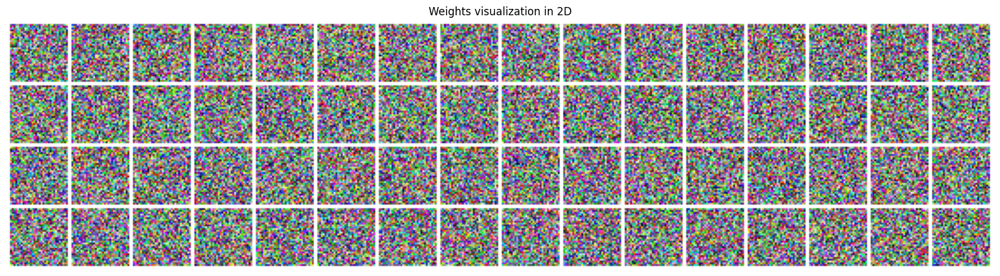

In [ ]:
import matplotlib.pyplot as plt
from torchvision import utils


W1 = fc_model.layers_stack[0].weight.reshape(64, 3, 32, 32)  # layer has 64 neurons
img_grid = utils.make_grid(W1, pad_value=1, normalize=True, nrow=16)

plt.figure(figsize=(20, 12))
plt.title("Weights visualization in 2D")
plt.imshow(img_grid.permute(1, 2, 0).cpu().numpy())  # CHW -> HWC
plt.axis("off")
plt.show()

## Нарушение связей между соседними пикселями

При вытягивании изображения в вектор мы теряем информацию о взаимном расположении пикселей на исходной картинке.





### Рецептивное поле

В полносвязной сети каждый нейрон "видит" сразу все изображение (все данные). Наша зрительная система работает иначе.

*  Каждый фоторецептор на сетчатке нашего глаза (палочка или колбочка) реагирует только на свет, попавший на него.

* Сигнал от фоторецептора попадает на нейрон следующего уровня ([биполярная клетка 📚[wiki]](https://ru.wikipedia.org/wiki/%D0%91%D0%B8%D0%BF%D0%BE%D0%BB%D1%8F%D1%80%D0%BD%D1%8B%D0%B5_%D0%BA%D0%BB%D0%B5%D1%82%D0%BA%D0%B8_%D1%81%D0%B5%D1%82%D1%87%D0%B0%D1%82%D0%BA%D0%B8)). Этот нейрон уже соединен с несколькими фоторецепторами. Область, в которой они локализованы, называется **рецептивным полем**.
Нейрон возбуждается при определенной комбинации сигналов от связанных с ним рецепторных клеток. По сути, он реагирует на простой, локально расположенный паттерн.

* Клетки уровнем выше (ганглиозные) собирают информацию с нескольких близко расположенных биполярных клеток и активируются при уникальной комбинации сигналов с них. Их рецептивное поле больше, и паттерны, на которые они реагируют, сложнее.

**Рецептивное поле** нейрона — это участок с рецепторами, с которых он прямо или опосредованно, через другие нейроны, получает информацию.


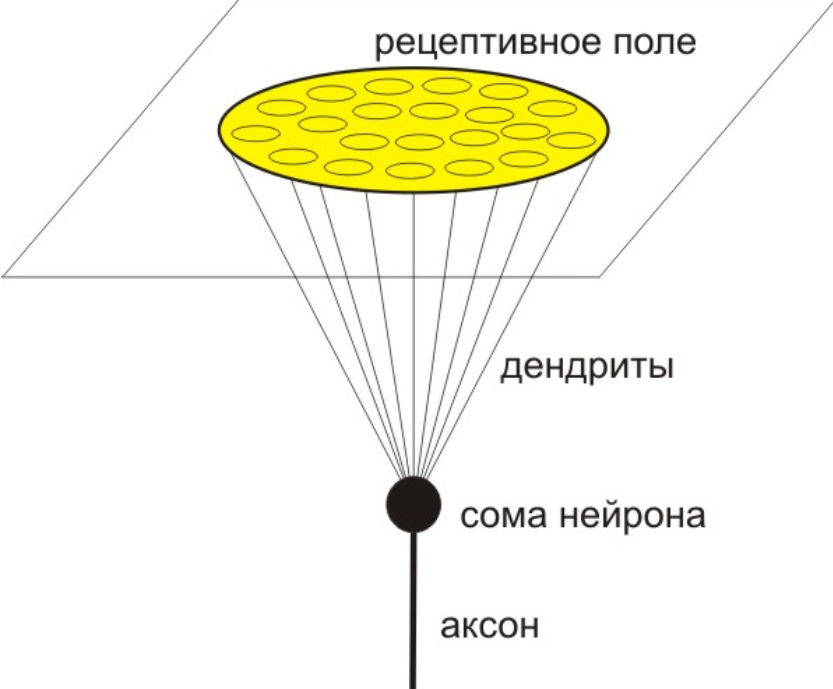


* Далее сигнал передается в мозг, но там связи между нейронами продолжают оставаться иерархическими. Рецептивное поле нейронов растет, и паттерны, на которые они активируются, становятся все более и более сложными.

### Скользящее окно (фильтр)

Получается, что можно не подавать на вход нейрона первого слоя информацию о всем изображении сразу, а "показать" ему только часть картинки, чтобы он научился распознавать простые, но универсальные паттерны. А их агрегация произойдет в последующих слоях.

Для этого используется так называемое "скользящее окно", которое двигается по изображению, захватывая на каждом шаге только небольшую область.

<img src ="https://upload.wikimedia.org/wikipedia/commons/9/90/CNN-filter-animation-1.gif?utm_source=commons.wikimedia.org&utm_campaign=index&utm_content=original" width="600">

## Свертка с фильтром

Операцию применения фильтра к изображению будем называть *сверткой*. Это определение не вполне соответствует [математическому 📚[wiki]](https://en.wikipedia.org/wiki/Convolution), но повсеместно используется в DL.

По своей сути операция свёртки — это та же самая взвешенная сумма с добавлением свободного члена, используемая в полносвязных линейных слоях.

В фильтрах [Собеля 📚[wiki]](https://ru.wikipedia.org/wiki/%D0%9E%D0%BF%D0%B5%D1%80%D0%B0%D1%82%D0%BE%D1%80_%D0%A1%D0%BE%D0%B1%D0%B5%D0%BB%D1%8F) и [Гаусса 📚[wiki]](https://en.wikipedia.org/wiki/Gaussian_blur) свободный член отсутствовал, но в дальнейшем мы будем его использовать.

Выполним свертку при помощи помощи линейного слоя: заменим код внутри цикла линейным слоем и убедимся, что результат вычислений не поменялся.

Ключевое отличие между линейным слоем и свёрткой заключается в том, что каждый нейрон линейного слоя получает на вход всё изображение сразу, а свёртка — небольшие фрагменты.

Так как при свертке для каждого фрагмента получаем свой отклик (признак), то для всего изображения получим уже массив признаков (feature map).




# Сверточный слой нейросети

В PyTorch есть класс `nn.Conv2d` [🛠️[doc]](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), который реализует операцию свертки для целого изображения.


In [ ]:
import torch
import numpy as np

# fmt: off
cross = np.array([[0, 0 ,0, 0, 0],
                  [0, 0, 0, 0, 0],
                  [0, 0, 0, 1, 0],
                  [0, 0, 1, 1, 1],
                  [0, 0, 0, 1, 0]])

kernel_cs = np.array([[-1, 1, -1],
                      [ 1, 1,  1],
                      [-1, 1, -1]])
# fmt: on

cross_in_tensor = torch.tensor(cross).float()

In [ ]:
from torch.nn import Conv2d

conv = Conv2d(
    in_channels=1,  # what's this ?
    out_channels=1,  # what's this ?
    kernel_size=(3, 3),  # kernel.shape == 3x3
    bias=False,
)
# conv2d accepts input of shape BxCxHxW
feature_map = conv(
    cross_in_tensor.unsqueeze(0).unsqueeze(0)  # HxW -> BxCxHxW
)  # add batch and channel dim
print(feature_map)

tensor([[[[ 0.0000,  0.2945,  0.1300],
          [ 0.2945,  0.4718,  0.1951],
          [ 0.0472,  0.4097, -0.0640]]]], grad_fn=<ConvolutionBackward0>)


Так как изначально ядро нашего единственного фильтра (нейрона) инициализированно случайными небольшими значениями, то на выходе получается набор ничего не значащих чисел. Убедимся, что слой работает так, как мы ожидали, подменив ядро:

In [ ]:
# data[0] because filter can have multiple kernels. see next chapter
conv.weight.data[0] = torch.tensor(kernel_cs)  # replace original kernel

feature_map = conv(
    cross_in_tensor.unsqueeze(0).unsqueeze(0)
)  # add batch and channel dim
print("Feature map for cross\n", feature_map)

Feature map for cross
 tensor([[[[ 0., -1.,  1.],
          [-1.,  1.,  0.],
          [ 1.,  0.,  5.]]]], grad_fn=<ConvolutionBackward0>)


При создании экземпляра объекта класса `nn.Conv2D` [🛠️[doc]](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) помимо размера ядра (`kernel_size`) мы передали в конструктор еще два параметра:

`in_channels = 1 ` и `out_channels = 1`

Разберемся, что они означают.

### Обработка цветных/многоканальных изображений

`in_channels` — это количество каналов входного тензора (изображения).

В примерах выше мы рассматривали [черно-белые 📚[wiki]](https://ru.wikipedia.org/wiki/Чёрно-белая_фотография) изображения. Их также называют одноканальными изображениями, т. к. в них цвет пикселя определяется одним числом, характеризующим яркость. Хранятся они в двумерном массиве размером $[H,W]$.

Цветные изображения хранятся в трехмерных массивах $[H,W,C]$ (для формата numpy, OpenCV) или $[C,H,W]$ (тензорный формат PyTorch), где $C$ — количество цветовых каналов.

Для $\text{RGB}$-изображений $C=3$. Такой же порядок $[C,H,W]$ присущ по умолчанию и спутниковым растрам формата geotiff при работе с ними в библиотеках  rasterio, gdal, rioxarray.

Так как `Conv2d` рассчитан на работу с многоканальным входом, то в коде выше нам пришлось написать дополнительный `unsqueeze(0)`, чтобы добавить к тензору с изображением это $3$-е измерение, т. е. перевести $[H,W]$ в $[C,H,W]$, где $C = 1$.

Важно, что для каждого канала будет создано дополнительное ядро фильтра.

In [ ]:
conv_ch1 = Conv2d(in_channels=1, out_channels=1, kernel_size=5)
print("One channel kernel \t", conv_ch1.weight.shape)
conv_ch3 = Conv2d(in_channels=3, out_channels=1, kernel_size=5)
print("Three channel kernel \t", conv_ch3.weight.shape)

One channel kernel 	 torch.Size([1, 1, 5, 5])
Three channel kernel 	 torch.Size([1, 3, 5, 5])


Опробуем трехканальную свертку на цветном изображении:

In [ ]:
! wget -q https://raw.githubusercontent.com/alexkalitenko125/Course-Neural-Networks-in-Quantum-Theory/refs/heads/main/cat.jpg

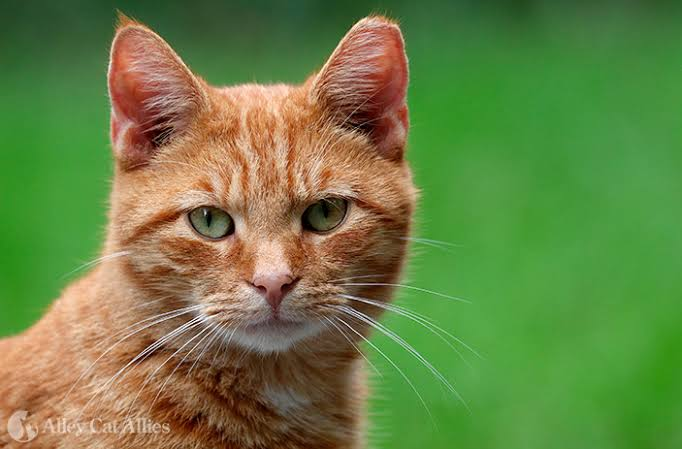

In [ ]:
from PIL import Image

cat_in_pil = Image.open("cat.jpg")
display(cat_in_pil)

Изображение из формата Pillow надо превратить в `torch.Tensor`:

In [ ]:
cat_in_np = np.array(cat_in_pil)  # pillow -> numpy
cat_in_float = cat_in_np.astype(np.float32) / 255  # int->float
cat_in_tensor = torch.tensor(cat_in_float)  # np -> torch

try:
    conv_ch3(cat_in_tensor.unsqueeze(0))  # add batch dimension
except Exception as e:
    print("Error: \n", e)

Error: 
 Given groups=1, weight of size [1, 3, 5, 5], expected input[1, 449, 682, 3] to have 3 channels, but got 449 channels instead


Получили ошибку, связанную с количеством каналов. Дело в том, что в PyTorch, в отличие от OpenCV, TensorFlow и ряда других библиотек, каналы (RGB) идут в первом, а не в последнем измерении тензора, описывающего картинку.

OpenCV, TensorFlow, Pillow, etc. : $[\text{Batch}, \text{Height}, \text{Width}, \text{Channels}]$

PyTorch : $[\text{Batch}, \text{Channels}, \text{Height}, \text{Width}]$

Придется сделать дополнительное преобразование, чтобы каналы оказались на том месте, где их ожидает PyTorch:

In [ ]:
print("Original \t", cat_in_tensor.shape, "HWC")
cat_in_tensor_channel_first = cat_in_tensor.permute(2, 0, 1)  # HWC -> CHW
print("Torch style \t", cat_in_tensor_channel_first.shape, "CHW")

Original 	 torch.Size([449, 682, 3]) HWC
Torch style 	 torch.Size([3, 449, 682]) CHW


Теперь можно подать изображение на вход модели, предварительно добавив batch-размерность:

In [ ]:
one_image_batch = cat_in_tensor_channel_first.unsqueeze(0)  # CHW -> BCHW, B = 1
out = conv_ch3(one_image_batch)
print("No error!")

No error!


Нет необходимости проделывать все эти манипуляции вручную, так как в `torchvision.transforms.v2` реализованы функции `to_image` [🛠️[doc]](https://pytorch.org/vision/main/generated/torchvision.transforms.v2.ToImage.html) и  `to_dtype` [🛠️[doc]](https://pytorch.org/vision/main/generated/torchvision.transforms.v2.ToDtype.html), которые последовательно выполняют  преобразования массива типа `np.array` или `Pillow.image` в класс `Image`, а затем в в `torch.Tensor`.

Убедимся, что тензор, преобразованный нами вручную, и тензор, получившийся после применения функции `to_image` и `to_dtype`, совпали:

In [ ]:
from torchvision.transforms.v2.functional import to_image, to_dtype


cat_in_image = to_image(cat_in_pil)  # convert np.array to PIL.image
cat_in_tensor2 = to_dtype(
    cat_in_image, dtype=torch.float32, scale=True
)  # auto HWC -> CHW

print(cat_in_tensor2.shape)

print(
    "Tensor almost equal: ",
    torch.allclose(cat_in_tensor_channel_first, cat_in_tensor2),  # float comparsion
)

torch.Size([3, 449, 682])
Tensor almost equal:  True


Теперь посмотрим на форму выхода, полученного нами ячейкой выше:

In [ ]:
print("Output feature map size:", out.shape)  # first dim is batch

Output feature map size: torch.Size([1, 1, 445, 678])


Такую размерность имеет выход  **единственного нейрона** в нашем сверточном слое.

На входе несколько каналов (3), на выходе остался один канал.
Как же комбинируются результаты сверток в разных каналах?



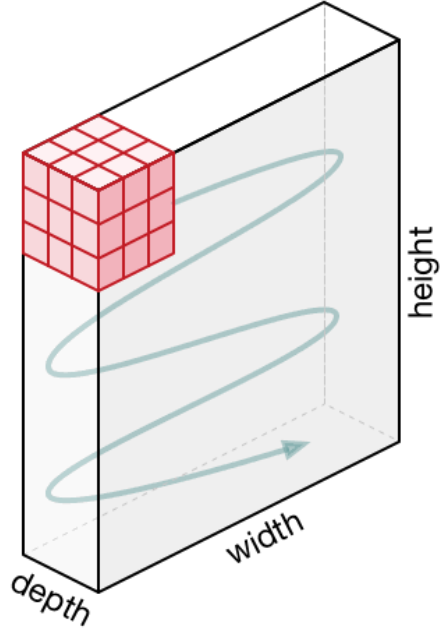

Результаты сверток всех ядер фильтра с соответствующими входными каналами просто суммируются:

$\large \displaystyle \text{feature_map}(x,y) = \sum_{c}^{C} \sum_{i}^{H} \sum_{j}^{W}k_c[i,j]I_c[x+j,y+i] + \text{bias},$

$C$ — количество каналов,

$H, W$ — высота и ширина ядра фильтра,

$K_c$ — ядро для канала $c$,

$I$ — изображение (массив $C\times H\times W$),

$I_c$ — канал изображения номер $c$ (срез массива $I$, соответствующий каналу изображения номер $c$).

В силу коммутативности суммы не важно, в каком порядке будут складываться элементы. Можно считать, что каждый элемент входа сначала умножается на свой коэффициент из ядра, а уже затем все суммируется.

In [ ]:
print("Kernels", conv_ch3.weight.shape)
print("Biases", conv_ch3.bias.shape)

Kernels torch.Size([1, 3, 5, 5])
Biases torch.Size([1])


Входные данные не всегда будут трехканальными цветными [RGB 📚[wiki]](https://ru.wikipedia.org/wiki/RGB)-изображениями, в которых цвет пикселя определяется тремя числами, характеризующими три основных цвета (красный, зеленый и синий).

Входной тензор может иметь произвольное количество каналов. Например: марсоход Opportunity для получения изображений использовал [13 каналов ✏️[blog]](https://habr.com/ru/post/160621/).

Более того, в качестве входного тензора можно использовать не входное изображение, а **карту признаков (feature map)** с выхода предыдущего сверточного слоя.


### Использование нескольких фильтров

Возвращаемся ко второму параметру конструктора `nn.Conv2D` —
`out_channels = 1`. Этот параметр задает количество фильтров слоя. То есть количество выходных карт признаков всегда совпадает с `out_channels` сверточного слоя.

In [ ]:
conv35 = Conv2d(in_channels=3, out_channels=5, kernel_size=3)
out = conv35(cat_in_tensor_channel_first)

print(f"weights shape: {conv35.weight.shape}")  # 5 filters 3x3x3
print(f"weights shape: {conv35.bias.shape}")  # one bias per filter

weights shape: torch.Size([5, 3, 3, 3])
weights shape: torch.Size([5])


В линейном слое каждый нейрон учился активироваться на некий шаблон, например, красную машину или смотрящую направо лошадь.

Мы хотим, чтобы нейроны сверточного слоя также активировались на различные паттерны (например, ухо, нос, глаз и т.д.). Для каждого паттерна нам нужен свой нейрон $⇒$ свой фильтр.

 Каждый нейрон сформирует свою карту признаков размера $1\times H_{out}\times W_{out}$. А на выходе слоя будет их конкатенация:

In [ ]:
print(f"result shape: {out.shape}")  # 5 feature maps

result shape: torch.Size([5, 447, 680])


При объединении этих карт получится тензор размерности $C_{out}\times H_{out} \times W_{out}$, где $C_{out}$ — количество фильтров.

Для **примера с Blur** $C_{out} = 1$, т. е. полученное сглаженное изображение представляет собой одну карту признаков после прохождения через сверточный слой с константным фильтром.


Стоит отметить, что, в отличие от полносвязного слоя, свёрточный слой не требует информации о количестве значений во входном представлении и может быть использован как для представлений $C_{in} \times 32 \times 32$, так и для $C_{in} \times 100 \times 100$. Словом, представления могут иметь практически любой размер, главное, чтобы пространственные размеры не были меньше размеров ядра свёртки.



### Уменьшение размера карты признаков

Карта признаков после применения функции активации может быть передана на вход следующей операции свёртки.

In [ ]:
from torch.nn.functional import relu

conv_1 = torch.nn.Conv2d(
    in_channels=3,  # Number of input channels (3 for RGB images)
    out_channels=6,  # Number of filters/output channels
    kernel_size=5,
)

conv_2 = torch.nn.Conv2d(
    in_channels=6,  # Number of input channels (3 for RGB images)
    out_channels=10,  # Number of filters/output channels
    kernel_size=5,
)

img = torch.randn((1, 3, 32, 32))  # 1-batch size, 3-num of channels, (32,32)-img size
print(f"img shape: {img.shape}")

out_1 = conv_1(img)
print(f"out_1 shape: {out_1.shape}")  # [1, 6, 28, 28]

out_2 = conv_2(relu(out_1))
print(f"out_2 shape: {out_2.shape}")  # [1, 10, 24, 24]

img shape: torch.Size([1, 3, 32, 32])
out_1 shape: torch.Size([1, 6, 28, 28])
out_2 shape: torch.Size([1, 10, 24, 24])


Заметим, что после свёртки ширина $W_{out}$ и высота $H_{out}$ **карты признаков** будут отличаться от **пространственных размерностей** $W_{in}$ и $H_{in}$ исходного тензора. К примеру, при обработке трёхканального тензора размера $32\times32$ ядром размера $5\times5$ можно будет произвести лишь $27$ сдвигов $(32 - 5)$ по вертикали и столько же по горизонтали. Но при этом размер итоговой карты признаков будет равен $28 \times 28$, поскольку первый ряд (либо столбец) можно получить без сдвигов по вертикали либо горизонтали соответственно. При повторном применении фильтра размер каждой из сторон уменьшится ещё на $4$.

Итоговое значение $N'$ пространственной размерности $N$ для квадратного фильтра $K \times K$ фильтра $F$ вычисляется по следующей формуле:
$$\large N' = N - K + 1$$.

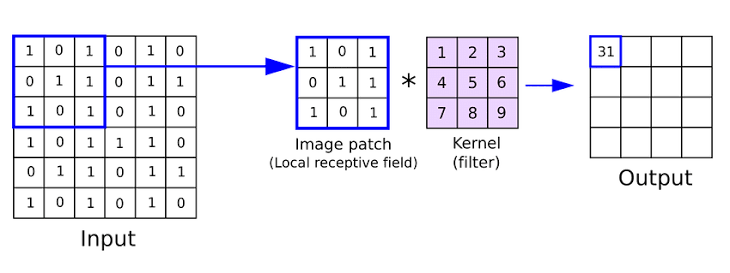

Заметим, что при уменьшении размера представлений пиксели, находящиеся около краёв, участвуют в значительно меньшем количестве свёрток, чем пиксели в середине, хотя информация в них не обязательно менее ценна, чем информация из центральных пикселей. К примеру, пиксель в верхнем левом углу представления вне зависимости от размера фильтра будет принимать участие лишь в одной свёртке, и информация о нём будет сохранена лишь в верхнем левом углу нового представления.

### Расширение (padding)

Для борьбы с описанной выше проблемой применяется *набивка/дополнение* входного тензора (англ. *padding*). В ходе него ширина и высота тензора увеличиваются за счёт приписывания столбцов и строк с некоторыми значениями. К примеру, на изображении ниже перед свёрткой ядром размера $3\times3$ был применён padding нулями.

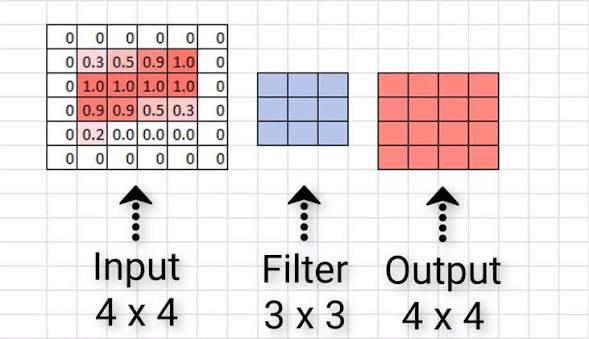

На примере убедимся, что это позволит нам сохранить пространственные размерности тензоров.

In [ ]:
img = torch.randn((1, 1, 5, 5))  # create random image BCHW
print(f"Original tensor:\nshape:{img.shape}")
conv_3 = torch.nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3)
conved_3 = conv_3(img)
print("Shape after convolution layer(kernel 3x3):", conved_3.shape)

Original tensor:
shape:torch.Size([1, 1, 5, 5])
Shape after convolution layer(kernel 3x3): torch.Size([1, 1, 3, 3])


Карта признаков меньше, чем вход. Теперь добавим padding:

In [ ]:
# Add zeros to image manually
padded_img = torch.zeros((1, 1, 7, 7))  # create zeros array to insert image in center
padded_img[:, :, 1:-1, 1:-1] += img  # insert image, we get image arounded by zeros
print(f"\nPadded tensor:\nshape:{padded_img.shape}:\n {padded_img}")

conved_pad_3 = conv_3(padded_img)
print("\n\nPadded shape:", padded_img.shape)
print("Shape after convolution with padding(kernel 3x3):", conved_pad_3.shape)


Padded tensor:
shape:torch.Size([1, 1, 7, 7]):
 tensor([[[[ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000],
          [ 0.0000, -2.1371,  0.4699,  0.7579,  1.1514, -0.8511,  0.0000],
          [ 0.0000,  3.2670, -0.0577,  0.1748,  0.3856,  1.4129,  0.0000],
          [ 0.0000, -0.4944, -0.5083,  0.8470, -1.9598,  0.4358,  0.0000],
          [ 0.0000,  0.6231, -0.3811, -0.1413,  0.7903, -0.4111,  0.0000],
          [ 0.0000, -0.0074,  1.1378, -1.7527,  1.8502,  1.2454,  0.0000],
          [ 0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000,  0.0000]]]])


Padded shape: torch.Size([1, 1, 7, 7])
Shape after convolution with padding(kernel 3x3): torch.Size([1, 1, 5, 5])


Размер выхода равен размеру входа.

Однако если мы увеличим размер ядра до $5\times5$, то увидим, что, несмотря на padding, выход снова стал меньше входа:

In [ ]:
conv_5 = torch.nn.Conv2d(in_channels=1, out_channels=1, kernel_size=5)

conved_pad_5 = conv_5(padded_img)

print("Original shape:", img.shape)
print("Shape after convolution with padding(kernel 5x5):", conved_pad_5.shape)

Original shape: torch.Size([1, 1, 5, 5])
Shape after convolution with padding(kernel 5x5): torch.Size([1, 1, 3, 3])


Дополнение одним рядом и одним столбцом не является универсальным решением: для фильтра размером $5$ размер выходного тензора всё равно отличается от входного. Если мы немного видоизменим полученную выше формулу (используя размер дополнения $P$), то получим:
$$\large N' = N + 2\cdot P - K + 1$$

Для того, чтобы пространственные размеры не изменялись ($N' = N$), для разных размеров фильтра требуются разные размеры дополнения. В общем случае для размера фильтра $K$ требуемый размер дополнения:
$$\large P = \frac{K-1}{2}$$




Теперь реализуем padding, используя инструменты библиотеки PyTorch, и сравним его с ручным добавлением padding:

In [ ]:
# conv layer without padding (padding=0 by default)
conv_3 = torch.nn.Conv2d(in_channels=1, out_channels=1, kernel_size=3, padding=0)

# conv layer with padding = 1 (add zeros)
conv_3_padded = torch.nn.Conv2d(
    in_channels=1, out_channels=1, kernel_size=3, padding=1
)  # Padding added 1 zeros line to all four sides of the input
original = conv_3(padded_img)
padded = conv_3_padded(img)

print(f"Explicitly padded:\n{original.shape}")
print(f"\nImplicitly padded:\n{padded.shape}")

Explicitly padded:
torch.Size([1, 1, 5, 5])

Implicitly padded:
torch.Size([1, 1, 5, 5])


Кроме чисел параметр `padding` может принимать значение `"same"` — тогда padding будет рассчитан автоматически так, чтобы размер выходного тензора не отличался от размера входного тензора, или `"valid"` — отсутствие дополнения.

По умолчанию `padding = 0`, а если его изменить на целочисленное значение, то края тензора будут дополняться нулями, как в примерах выше. Это тоже не универсальный способ обработки краев изображения при свертках. Есть модификации: например, в `numpy.pad` [🛠️[doc]](https://numpy.org/doc/stable/reference/generated/numpy.pad.html) есть зеркальный padding или заполнение средним значением.

# Применение свёрточных слоёв

Теперь мы можем заменить часть линейных слоев нашей модели на сверточные. Но если решается задача классификации, то последний слой по-прежнему должен быть линейным.

Поскольку операция свертки является линейной (мы убедились в этом, когда выполняли ее при помощи линейного слоя), то функция активации (например, ReLU) по-прежнему требуется.

>*Так как функция активации применяется к тензору поэлементно, не важно, какую именно форму имеет тензор, а значит и какой слой находился перед ней: полносвязный или сверточный.*

Простейшая модель для MNIST может выглядеть примерно так:

In [ ]:
import torch
from torch import nn

batch_size = 1
input = torch.randn((batch_size, 1, 28, 28))

model = torch.nn.Sequential(
    nn.Conv2d(
        in_channels=1, out_channels=3, kernel_size=5
    ),  # after conv shape: [batch_size,3,24,24]
    nn.ReLU(),  # Activation doesn't depend on input shape
    nn.Conv2d(
        in_channels=3, out_channels=6, kernel_size=3
    ),  # after conv shape: [batch_size,6,22,22]
    nn.ReLU(),
    nn.Flatten(),  # 6*22*22=2904
    nn.Linear(2904, 100),
    nn.ReLU(),  # Activation doesn't depend on input shape
    nn.Linear(100, 10),  # 10 classes, like a cifar10
)

out = model(input)
print(f"out shape: {out.shape}")

out shape: torch.Size([1, 10])


Поскольку полносвязный слой принимает на вход набор векторов, а сверточный — возвращает набор трёхмерных тензоров, нам нужно превратить эти тензоры в векторы. Для этого используется объект класса `nn.Flatten` [🛠️[doc]](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html#torch.nn.Flatten).
Он преобразовывает данные на входе в вектор, сохраняя при этом первое (batch) измерение.

Ниже примеры других функций, которыми можно выполнить аналогичное преобразование:

In [ ]:
input = torch.randn((16, 3, 32, 32))

batch_size = input.shape[0]

print("class Flatten\t", nn.Flatten()(input).shape)
print(
    "view \t\t", input.view(batch_size, -1).shape
)  # data stay in same place in memory
print("reshape \t", input.reshape(batch_size, -1).shape)  # data may be moved
print("method flatten \t", input.flatten(1).shape)

class Flatten	 torch.Size([16, 3072])
view 		 torch.Size([16, 3072])
reshape 	 torch.Size([16, 3072])
method flatten 	 torch.Size([16, 3072])


### Рецептивные поля нейронов

Нейросетевая модель из предыдущего примера позволяет в общем случае понять структуру свёрточных нейронных сетей: после некоторого количества свёрточных слоёв, извлекающих локальную пространственную информацию, идут полносвязные слои (как минимум в количестве одного), сопоставляющие извлечённую информацию.

Внутри свёрточных слоёв происходит следующий процесс: первые слои нейронных сетей имеют малые рецептивные поля, т. е. им соответствует малая площадь на исходном изображении. Такие нейроны могут активироваться лишь на некоторые простые шаблоны (по типу углов или освещённости).

Нейроны следующего слоя уже имеют большие рецептивные поля, в результате чего в картах признаков появляется информация о более сложных паттернах. С каждым слоем свёрточной нейронной сети рецептивное поле нейронов увеличивается. Увеличивается и сложность шаблонов, на которые может реагировать нейрон. В последних слоях рецептивное поле нейрона должно быть размером со всё исходное изображение.

Если на первом слое рецептивное поле имело размер $K \times K$, то после свёртки фильтром $K\times K$ оно стало иметь размер $(2K-1) \times (2K-1)$, то есть увеличилось на $K-1$ по каждому из направлений. Несложно самостоятельно убедиться, что данная закономерность сохранится при дальнейшем применении фильтров того или иного размера.



Однако при обработке больших изображений нам потребуется очень много слоев, чтобы нейрон "увидел" всю картинку.

К примеру, для изображения $1024\times1024$ понадобится сеть глубиной $\approx510$ сверточных слоев.

Такая модель потребует огромного количества памяти и вычислительных ресурсов.
Чтобы избежать этого, будем сами уменьшать размеры карт признаков, при этом рецептивные поля нейронов будут расти.



### Шаг свёртки (Stride)

До этого мы двигали фильтр на один пиксель, то есть перемещались с шагом (stride), равным единице.

Если двигать фильтр с большим шагом, то размер выходной карты признаков (feature map) будет уменьшаться кратно шагу, и рецептивные поля нейронов будут расти быстрее.

Для изменения шага свертки в конструкторе `nn.Conv2d` [🛠️[doc]](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html) есть параметр `stride`.

In [ ]:
dummy_input = torch.randn(1, 1, 5, 5)
conv_s1 = nn.Conv2d(in_channels=1, out_channels=3, kernel_size=3, stride=(1, 1))
conv_s2 = nn.Conv2d(1, 3, 3, stride=2)  # bypass par. names, stride = (2, 2)

out_stride1 = conv_s1(dummy_input)
out_stride2 = conv_s2(dummy_input)

print("Out with stride 1", out_stride1.shape)
print("Out with stride 2", out_stride2.shape)

Out with stride 1 torch.Size([1, 3, 3, 3])
Out with stride 2 torch.Size([1, 3, 2, 2])


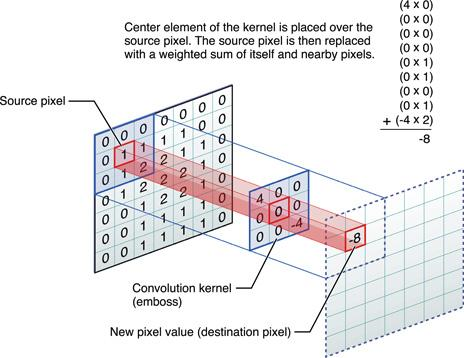

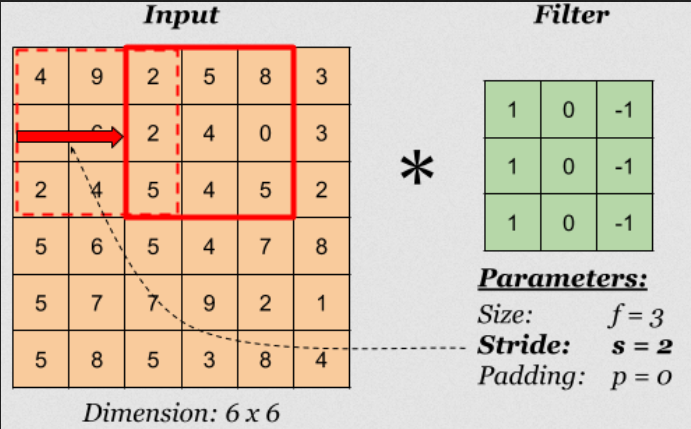

Важно заметить, что в некоторых случаях часть данных может не попасть в свёртку. К примеру, при $N = 7,\, K = 3,\, S = 3$. В данном случае: $$\large N' = 1 + \frac{7 - 3}{3} = 2\frac13$$
 В подобных ситуациях часть изображения не захватывается, в чём мы можем убедиться на наглядном примере:

In [ ]:
# Create torch tensor 7x7
# fmt: off
input = torch.tensor([[[[1, 1, 1, 1, 1, 1, 99],
                        [1, 1, 1, 1, 1, 1, 99],
                        [1, 1, 1, 1, 1, 1, 99],
                        [1, 1, 1, 1, 1, 1, 99],
                        [1, 1, 1, 1, 1, 1, 99],
                        [1, 1, 1, 1, 1, 1, 99],
                        [1, 1, 1, 1, 1, 1, 99]]]], dtype=torch.float)
# fmt: on

print(f"input shape: {input.shape}")

conv = torch.nn.Conv2d(
    in_channels=1,  # Number of channels
    out_channels=1,  # Number of filters
    kernel_size=3,
    stride=3,
    bias=False,  # Don't use bias
)
conv.weight = torch.nn.Parameter(
    torch.ones((1, 1, 3, 3))
)  # Replace random weights to ones
out = conv(input)

print(f"out shape: {out.shape}")
print(f"out:\n{out}")

input shape: torch.Size([1, 1, 7, 7])
out shape: torch.Size([1, 1, 2, 2])
out:
tensor([[[[9., 9.],
          [9., 9.]]]], grad_fn=<ConvolutionBackward0>)


Видно, что столбец с числами $99$ просто не попал в свертку.
Поэтому на практике подбирают `padding` таким образом, чтобы при `stride = 1`  размер карты признаков на выходе был равен входу, а затем делают свертку со `stride = 2`.

Казалось бы, с увеличением шага $S$ рецептивное поле не выросло — как увеличивалось с $1$ до $K$, так и увеличивается. Однако обратим внимание на другое: если раньше размерность $N$ становилась $N - K + 1$, то теперь она станет $\displaystyle 1 + \frac{N-F}{S}$.

В результате если раньше следующий фильтр с размером $K'$ имел рецептивное поле:$$\displaystyle N \cdot \frac{K'}{N'} = N \cdot \frac{K'}{N - K + 1},$$

то теперь: $$N \cdot \frac{K'}{N'} = N \cdot \frac{K'}{1 + \dfrac{N-K}{S}}.$$

Понятно, что $$\frac{K'}{N - F + 1} \leq \frac{K'}{1 + \dfrac{N-K}{S}},$$ поэтому рецептивное поле каждого нейрона увеличивается.

### Уплотнение (Субдискретизация, Pooling)

Другим вариантом стремительного увеличения размера рецептивного поля является использование дополнительных слоёв, требующих меньшего количества вычислительных ресурсов. Слои субдискретизации прекрасно выполняют эту функцию: подобно свёртке производится разбиение изображения на небольшие сегменты, внутри которых выполняются операции, не требующие использования обучаемых весов. Два популярных примера подобных операций: получение максимального значения (max pooling) и получение среднего значения (average pooling).

**Важно понимать**, что pooling-слои не являются сверточными слоями, так как в них нет фильтров с обучаемыми весами, т. е. они никак не настриваются в процессе обучения нейросети. Это просто эффективный способ уменьшить пространственные размеры карт признаков.

Аналогично разбиению на сегменты при свёртке, слои субдискретизации имеют два параметра: размер фильтра $K$ (то есть, каждого из сегментов) и шаг $S$ (stride). Аналогично свёрткам, при применении субдискретизации формула размера стороны:
$$N' = 1+ \frac{N-K}{S}.$$

Ниже приведён пример использования операций max pooling и average pooling при обработке массива.

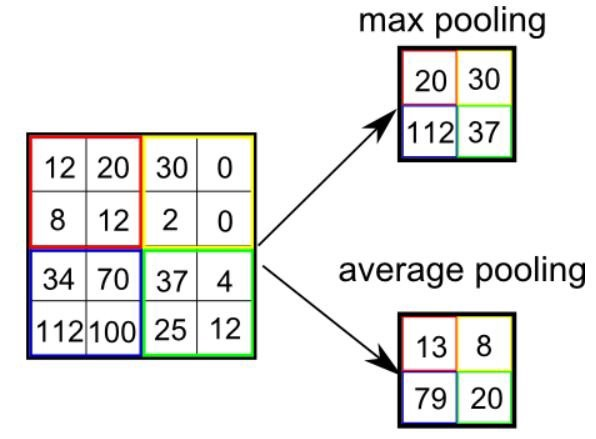

Реализуем это в коде:

In [ ]:
# create tensor 4x4
# fmt: off
input = torch.tensor([[[[1, 1, 2, 4],
                        [5, 6, 7, 8],
                        [3, 2, 1, 0],
                        [1, 2, 3, 4]]]], dtype=torch.float)
# fmt: on

max_pool = torch.nn.MaxPool2d(kernel_size=2, stride=2)
avg_pool = torch.nn.AvgPool2d(kernel_size=2, stride=2)

print("Input:\n", input)
print("Max pooling:\n", max_pool(input))
print("Average pooling:\n", avg_pool(input))

Input:
 tensor([[[[1., 1., 2., 4.],
          [5., 6., 7., 8.],
          [3., 2., 1., 0.],
          [1., 2., 3., 4.]]]])
Max pooling:
 tensor([[[[6., 8.],
          [3., 4.]]]])
Average pooling:
 tensor([[[[3.2500, 5.2500],
          [2.0000, 2.0000]]]])


**Важно отметить**, что субдискретизация выполняется по каждому из каналов отдельно, в результате чего количество каналов не меняется, в отличие от применения фильтра при свёртке!

Давайте зафиксируем эту разницу еще четче:

• Субдискретизация (Pooling / Пулинг): Работает как «независимый уменьшитель размера». Если на вход приходит тензор размером $H \times W \times C$ (где $C$ — количество каналов), то операция пулинга применяется к каждому каналу $C$ отдельно. Изменяются только высота $H$ и ширина $W$, а количество каналов $C$ остается абсолютно прежним.

• Свёртка (Convolution): Работает как «смешиватель каналов». Каждый фильтр слоя свёртки имеет глубину, равную количеству входных каналов, и сканирует их все одновременно, суммируя результаты. В итоге один фильтр выдает одну карту признаков (один канал). Поэтому количество выходных каналов строго равно количеству примененных фильтров и никак не зависит от исходного числа каналов.

### Свёртка фильтром $1\times1$

С помощью субдискретизации и свертки с шагом больше единицы мы можем регулировать пространственные размеры (ширину и высоту) карты признаков.

Обычно если хотят уменьшить количество каналов в карте признаков, то используют свертку с размерами ядра $1\times1$.

Так, например, работает и [фильтр Собеля 📚[wiki]](https://ru.wikipedia.org/wiki/%D0%9E%D0%BF%D0%B5%D1%80%D0%B0%D1%82%D0%BE%D1%80_%D0%A1%D0%BE%D0%B1%D0%B5%D0%BB%D1%8F). В нем используются два фильтра — горизонтальный и вертикальный, которые затем объединяются путем свертки $1 \times 1$. Объединяя горизонтальные и вертикальные границы, мы получаем общую карту признаков-контуров изображения.

Фактически такая свертка — это линейный слой, на вход которому подали все признаки из одной точки входа.

Когда переводим цветное изображение в градации серого, мы делаем похожую операцию: складываем все каналы с коэффициентом $\displaystyle\frac{1}{3}$:

$\text{Brightness} = \dfrac{1}{3} R + \dfrac{1}{3} G + \dfrac{1}{3}B $

Количество каналов можно регулировать при помощи параметра `out_channels`. Если при этом количество каналов уменьшается, то таким образом мы обобщаем признаки.


При этом количество таких фильтров $1\times1$ может быть произвольным. Обычно свертку $1\times1$ применяют для уменьшения числа каналов, но и обратная ситуация тоже возможна.

Ниже приведён пример применения такого фильтра с целью снижения количества карт признаков.

In [ ]:
conv = torch.nn.Conv2d(
    in_channels=64,  # number of input channels
    out_channels=32,  # number of filters
    kernel_size=1,
)

input = torch.randn((1, 64, 56, 56))
out = conv(input)

print("Input shape:", input.shape)
print("Shape after 1x1 conv:", out.shape)  # [1, 32, 56, 56] batch, C_out, H_out, W_out

Input shape: torch.Size([1, 64, 56, 56])
Shape after 1x1 conv: torch.Size([1, 32, 56, 56])


### Сравнение свёрточного и полносвязного слоев

Давайте оценим количество ресурсов, которое требуется для обработки одного изображения из CIFAR-10 при помощи сверточного и полносвязного слоя.

Пусть сверточный слой будет содержать $6$ фильтров размером $3 \times 3 $, `padding = 1`, `stride = 1`, а полносвязный — $6$ выходов (как если бы мы делали классификацию $6$-ти классов).

#### Количество обучаемых праметров (весов) свёрточного слоя

Количество параметров в одном фильтре: $C_{in}\times K_{h}\times K_{w} + \text{bias} = 3 \times 3 \times 3 + 1 = 28$

Количество фильтров $C_{out} = 6$

Итого: $(C_{in}\times K_{h}\times K_{w} +1) \times C_{out} = 28 \times 6 = 168$



In [ ]:
from torch.nn import Conv2d


def get_params_count(module):
    weights_count = 0
    # Get all model weights: kernels + biases
    for p in module.parameters():
        print(p.shape)
        # torch.prod - multiply all values in tensor
        weights_count += torch.tensor(p.shape).prod()
    print("Total weights", weights_count.item())


conv = Conv2d(3, 6, 3, bias=True)
get_params_count(conv)

torch.Size([6, 3, 3, 3])
torch.Size([6])
Total weights 168


#### Количество обучаемых праметров полносвязного слоя

1. Данные вытягиваем в вектор:

$\text{inputs_count} = C_{in} \times H_{in} \times W_{in}  = 3*32*32 = 3072$

2. Каждый нейрон (их $6$ шт.) выходного слоя хранит вес для каждого элемента входа ($3072$) и еще одно смещение:

$(\text{inputs_count} + 1) \times \text{outputs_count} = (3072 + 1) \times 6 = 18\ 438$


In [ ]:
from torch.nn import Linear

linear = Linear(3072, 6, bias=True)
get_params_count(linear)

torch.Size([6, 3072])
torch.Size([6])
Total weights 18438


То есть для хранения весов такого линейного слоя нужно в $\approx 100$ раз больше памяти.

#### Количество требуемых вычислительных ресурсов для полносвязного слоя

*Считаем только умножения, т. к. (умножение + сложение = 1 [FLOP 📚[wiki]](https://en.wikipedia.org/wiki/FLOPS)).*

В полносвязном слое каждый вход умножается на свой вес один раз и количество умножений совпадает с количеством весов за вычетом сложения со смещением:

 $C_{in} × H_{in} × W_{in} × \text{outputs_count}  = 3 × 32 \times 32 × 6 = 18 \ 432 $

#### Количество требуемых вычислительных ресурсов для свёрточного слоя

1. Разовое применение фильтра эквивалентно применению линейного слоя с таким же количеством весов:

$C_{in} \times K_{h} \times K_{w} \times C_{out} = 3 \times 3 \times 3 \times 6 = 162$

Т. е. умножаем каждый вес фильтра на вход.

2. Сдвигаем фильтр и повторяем п. 1 для каждой точки на карте признаков:

$C_{in} \times K_{h} \times K_{w} \times C_{out} \times H_{out} \times W_{out}   = 162 \times 32 \times 32  = 165\ 888 $

То есть количество операций в $\approx 10$ раз больше, чем у полносвязного слоя.

**Выводы**:
выигрыш по количеству параметров при использовании свёрточного слоя омрачается большим количеством операций перемножения. Это было проблемой в течение долгого времени, пока вычисление операции свёртки не перевели на видеокарты (Graphical Processing Unit). При выполнении свёртки одного сегмента не требуется информация о результатах свёртки на другом сегменте, поэтому данные операции можно выполнять параллельно, с чем как раз прекрасно справляются видеокарты.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Conv2d(in_channels=1, out_channels=6, kernel_size=3)
model.to(device)  # send model to device

dummy_input = torch.randn(1, 1, 5, 5)
out = model(dummy_input.to(device))  # send data to GPU too!
# ... do backprop if need
out = out.cpu()  # move data back to main memory

## Общая структура свёрточной нейронной сети

Теперь мы можем более детально взглянуть на типичную архитектуру свёрточной нейронной сети. Как ранее уже обсуждалось, в первую очередь необходимо последовательностью свёрточных слоёв и уплотнений достичь того, чтобы каждый элемент карты признаков имел большое рецептивное поле, а значит мог отвечать за большие и сложные шаблоны. Затем данные карты признаков выпрямляются в векторы и передаются в полносвязные слои, последовательность которых, используя глобальную информацию, возвращает значение целевой переменной.

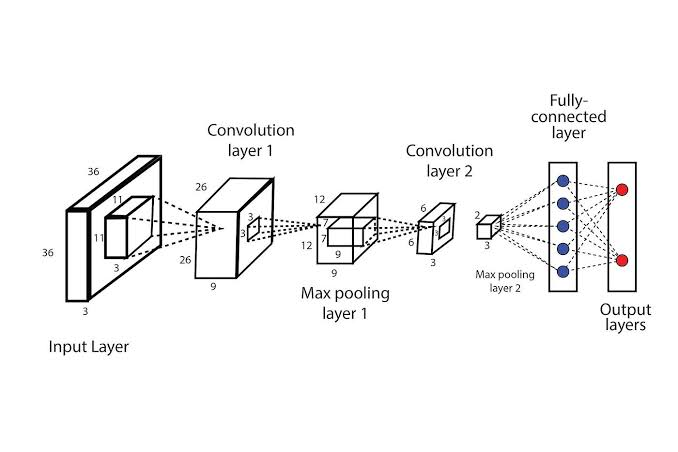

В результате количество признаков уменьшается от слоя к слою.

**Важно отметить** следующие эмпирические соображения по созданию собственной архитектуры сверточной нейросети:

* В первом сверточном слое сети обычно происходит резкое увеличение карт признаков с 1 или 3 (черно-белое или цветное изображение соответственно) до 16 и более.
* В последующих сверточных слоях периодически **пространственные размеры карт признаков уменьшают вдвое** (за счет pooling-слоев или за счет свертки с шагом $2$).
* Одновременно с уменьшением пространственных размеров карт признаков вдвое, **количество карт признаков увеличивают вдвое**.
* Полносвязные слои (FC) ставятся в конце сети в количестве обычно не больше двух. Они нужны только для формирования предсказаний на основе признаков, качественно извлеченных сверточной частью сети. FC слои сами по себе имеют большое число параметров, и при использовании большого количества полносвязных слоев модель может оказаться перепараметризована. Перепараметризация модели может приводить к переобучению, особенно при малом размере обучающей выборки.

### LeNet: пример архитектуры сверточной сети

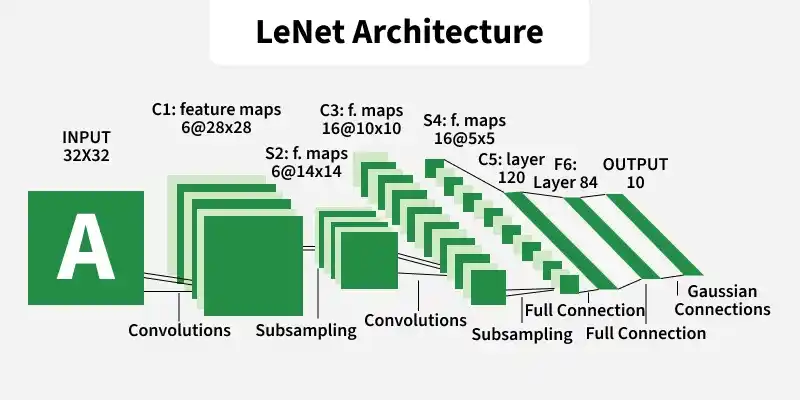

Примером сети, построенной по такой архитектуре, является LeNet.
Она была разработана в 1989 г. [Яном Ле Куном 📚[wiki]](https://en.wikipedia.org/wiki/Yann_LeCun). Сеть имела 5 слоев с обучаемыми весами, из них 2 — сверточные.

Применялась в США для распознавания рукописных чисел на почтовых конвертах до начала 2000 г.

[[doc] 🛠️ LeNet PyTorch documentation](https://pytorch.org/tutorials/beginner/blitz/neural_networks_tutorial.html)


In [ ]:
import torch
import torch.nn.functional as F
from torch import nn


class LeNetFeatExtractor(nn.Module):
    def __init__(self):
        super(LeNetFeatExtractor, self).__init__()
        self.conv1 = nn.Conv2d(1, 128, 3)
        self.conv2 = nn.Conv2d(128, 16, 3)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.conv1(x)), (2, 2))
        x = F.max_pool2d(F.relu(self.conv2(x)), 2)
        return x


class LeNetClassifier(nn.Module):
    def __init__(self):
        super(LeNetClassifier, self).__init__()
        self.fc1 = nn.Linear(16 * 6 * 6, 120)
        self.fc2 = nn.Linear(120, 84)
        self.fc3 = nn.Linear(84, 10)

    def forward(self, x):
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = self.fc3(x)
        return x


class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        self.feat = LeNetFeatExtractor()
        self.classifer = LeNetClassifier()

    def forward(self, x):
        x = self.feat(x)
        x = self.classifer(x)
        return x

Проверим, что сеть работает:

In [ ]:
my_LeNet = LeNet()
input = torch.randn(1, 1, 32, 32)
out = my_LeNet(input)
print(out.shape)

torch.Size([1, 10])


Процесс обучения почти не отличается от обучения полносвязной сети, используются такие же оптимизатор и функция потерь.

# Другие виды сверток


## 1D

Сигнал, который мы обрабатываем при помощи сверточного слоя, не обязательно должен быть картинкой и не обязательно должен быть двумерным.

В качестве примера такого сигнала может выступать звук:

In [ ]:
import torchaudio

dataset = torchaudio.datasets.YESNO("./", download=True)

100%|██████████| 4.49M/4.49M [00:01<00:00, 2.40MB/s]


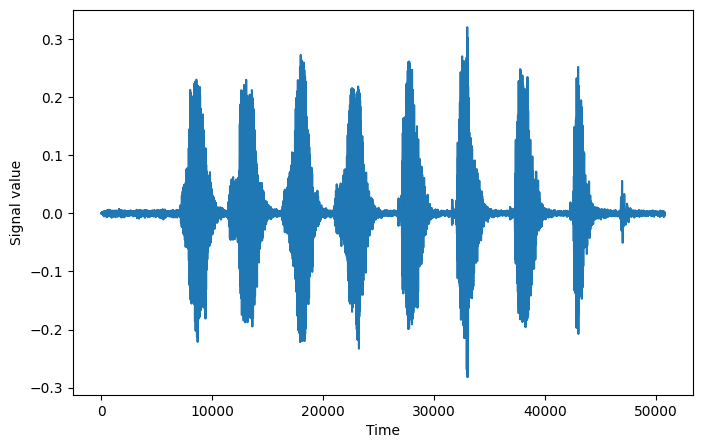

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.xlabel("Time")
plt.ylabel("Signal value")

waveform, sample_rate, label = dataset[0]

plt.plot(waveform.flatten())
plt.show()

В PyTorch одномерная свертка задается аналогично двумерной — `torch.nn.Conv1d` [🛠️[doc]](https://pytorch.org/docs/stable/generated/torch.nn.Conv1d.html):

```python
torch.nn.Conv1d(in_channels, out_channels, kernel_size, stride=1, padding=0, ...)
```

In [ ]:
from torch import nn

conv = nn.Conv1d(1, 16, 3, stride=2)
output = conv(waveform)
print(output.shape)

torch.Size([16, 25399])


Но такой сигнал чаще преобразуют в спектрограмму, а к ней уже можно применить 2D-свёртку:

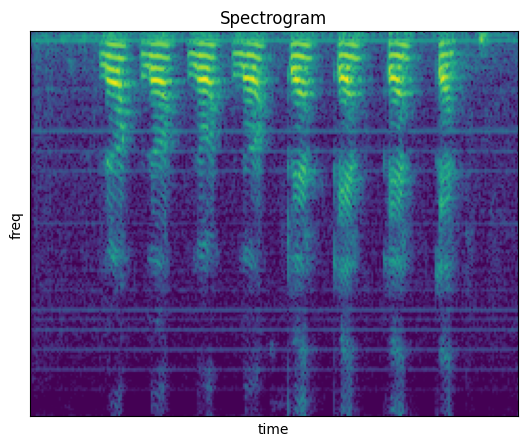

In [ ]:
import librosa
from torchaudio.transforms import Spectrogram


spec_obj = Spectrogram(power=2, center=True, pad_mode="reflect")
spec = spec_obj(waveform[0])

plt.figure(figsize=(7, 5))
plt.imshow(librosa.power_to_db(spec))
plt.title("Spectrogram")
plt.xlabel("time")
plt.ylabel("freq")
plt.xticks([], [])
plt.yticks([], [])
plt.show()

Другим примером могут являться, например, **спектрограммы растворов**.

#### Математический смысл одномерной свертки

Рассмотрим, как выглядит операция свертки в функциональном анализе.

Есть две различные функции, определяющие локальную "схожесть" функций $f(t)$ и $g(t)$:
- взаимнокорреляционная функция обозначается пятиконечной звездой <font size="8">$\large ⋆$</font> и определяет схожесть двух функций:
$$(f ⋆ g)(t)\stackrel{def}{=}  \int\limits_{-\infty}^{\infty}  f(\tau)g(t+\tau)d\tau$$
- свертка обозначается звездочкой (астериском) <font size="8">$*$</font> и определяет схожесть одной функции и "отраженной" другой функции:
$$\large(f * g)(t)\stackrel{def}{=}  \int\limits_{-\infty}^{\infty}  f(\tau)g(t-\tau)d\tau$$

Взаимная корреляция более интуитивно понятна: она представляет собой "наложение" шаблона на функцию, а свертка &mdash; "наложение" отраженного шаблона. Эти функции взаимосвязаны:
$$f(t) ⋆ g(t) = f(-t) * g(t)$$

Можно представить свертку как площадь произведения двух функций внутри скользящего окна.

В машинном обучении под словом **convolution** как правило [подразумевают **взаимнокорреляционную функцию** ✏️[blog]](https://glassboxmedicine.com/2019/07/26/convolution-vs-cross-correlation/), а не свертку. В реальности при обучении нейронной сети совершенно неважно, используется ли свертка или взаимнокорреляционная функция — они отличаются лишь порядком расположения весов внутри тензора ядра.

В случае дискретных величин для вычисления взаимной корреляции сигнал $f(t)$ поэлементно умножается со смещенным ядром $g(t)$, и результат суммируется:

$$\large(f \star g)(t) = f(1)g(t+1) + f(2)g(t+2) + f(3)g(t+3) + ...$$

Одномерная операция свертки используется для данных, имеющих последовательную структуру: текстов, аудиозаписей, цифровых сигналов. Как правило, такую структуру можно представить в виде изменения величины с течением времени.

Данные связаны в одном измерении — временном. Их тоже можно обработать при помощи свертки, но уже в одном измерении.

# Визуализация


Чтобы лучше понять, как работают сверточные сети, можно визуализировать карты признаков и веса фильтров свёртки.

## Визуализация весов

Веса фильтров на первом слое легко визуализировать. И результат легко интерпретируется, так как у фильтров такое же количество каналов, как и у цветных изображений ($3$ канала).

Ниже приведен пример того, как это можно сделать для обученной модели AlexNet из зоопарка моделей torchvision.

Чтобы понять, через какие свойства можно получить доступ к весам, выведем структуру модели

In [ ]:
from torchvision import models

alexnet = models.alexnet(weights="AlexNet_Weights.DEFAULT")
print(alexnet)

Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 186MB/s]


AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)
    (1): Linear(in_features=9216, out_features=4096, bias=True)
 

Видно, что первый слой — это $0$-й элемент контейнера `features`.
Веса слоя хранятся в `weight.data`.

In [ ]:
weight_tensor = alexnet.features[0].weight.data  # extract weights
print("Weights shape", weight_tensor.shape)

Weights shape torch.Size([64, 3, 11, 11])


Чтобы отобразить все веса на одном изображении, воспользуемся вспомогательной функцией `make_grid` [🛠️[doc]](https://pytorch.org/vision/stable/generated/torchvision.utils.make_grid.html#make-grid) из `torchvision.utils` [🛠️[doc]](https://pytorch.org/vision/stable/utils.html).

На вход метод получает `batch` изображений ($B \times C \times H \times W$) в формате `torch.Tensor` и визуализирует их в форме таблице.

In [ ]:
from torchvision import utils

img_grid = utils.make_grid(
    (weight_tensor + 1) / 2, pad_value=1
)  # combine weights from all channel into table, note remapping to (0,1) range
print("Output is CxHxW image", img_grid.shape)

Output is CxHxW image torch.Size([3, 106, 106])


`make_grid` часто используют, чтобы отображать изображения в TensorBoard.

А чтобы отобразить получившуюся таблицу в блокноте средствами matplotlib, нам потребуется поменять порядок хранения данных, поместив каналы на первое место.

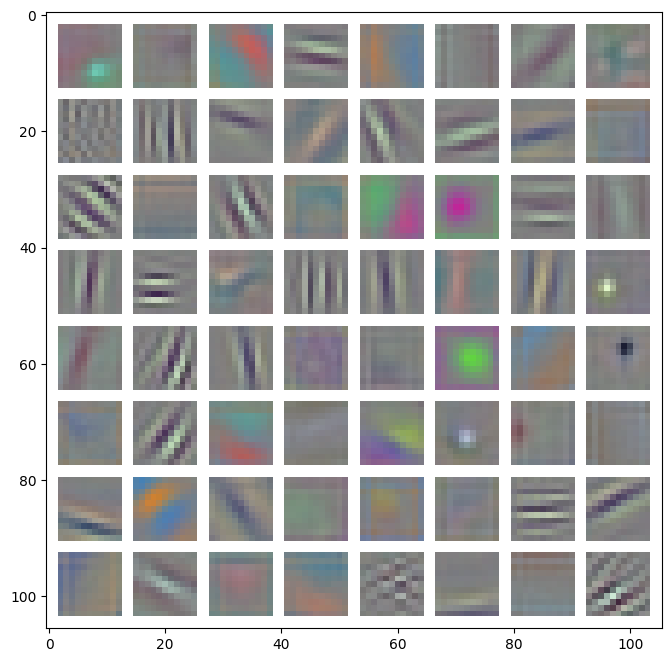

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


plt.rcParams["figure.figsize"] = (8, 8)
plt.imshow(
    np.transpose(img_grid, (1, 2, 0))
)  # change channel order for compability with numpy & matplotlib
plt.show()

Видно, что модель научилась улавливать простые геометрические формы: края под разными углами, точки того или иного цвета. Фильтры AlexNet'а оказались настолько большими, что частично захватили не только простую локальную информацию, но и сложные градиенты или решётки.


### Визуализация фильтров промежуточных слоев

К сожалению, выполнить ту же операцию для фильтров на скрытых слоях едва ли представляется разумным: в отличие от трёхканальных фильтров первого слоя, веса которых легко визуализировать, фильтры поздних слоёв имеют гораздо больше каналов, что затрудняет их визуализацию. Пожалуй, единственным вариантом  является поканальное отображение весов, которое довольно сложно трактовать. Убедимся в этом, на примере ниже.

Визуализируем веса $2$-го сверточного слоя AlexNet.
Слой доступен через `features[3] `

In [ ]:
weights_of_conv2_layer = alexnet.features[3].weight.data  # extract weights
print(weights_of_conv2_layer.shape)

torch.Size([192, 64, 5, 5])


В нем $192$ фильтра, в каждом $64$ ядра. Поэтому ограничимся первым фильтром и выведем все его ядра.

In [ ]:
first_filter_kernels = weights_of_conv2_layer[0]
print(first_filter_kernels.shape)

torch.Size([64, 5, 5])


Чтобы использовать `image_grid`, входной тензор должен иметь формат $(B \times C \times H \times W)$. Поэтому добавим размерность, соответствующую каналам:

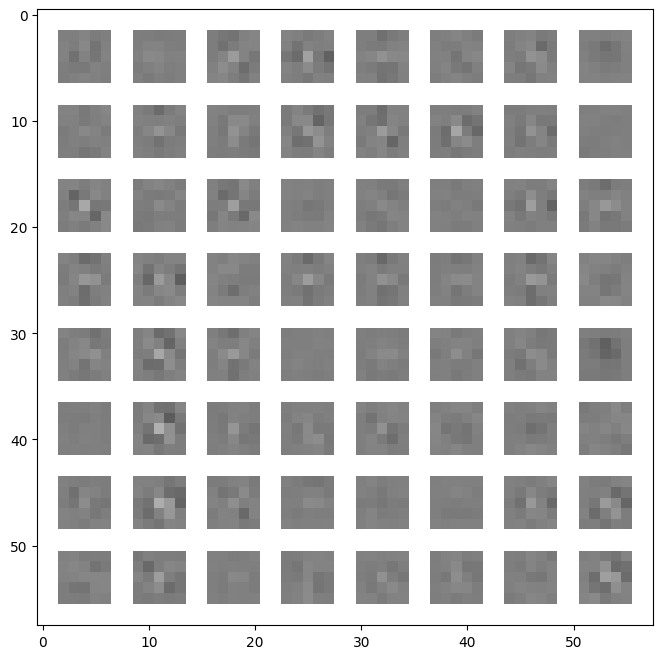

In [ ]:
img_grid = utils.make_grid(
    weights_of_conv2_layer[0].unsqueeze(1), pad_value=1  # add fake channel dim
)

plt.rcParams["figure.figsize"] = (8, 8)
plt.imshow(
    np.transpose((img_grid + 1) / 2, (1, 2, 0))
)  # change channel order for compability with numpy
plt.show()

Интерпретация такой визуализации довольно затруднительна, зато мы разобрались, как получать доступ к весам.

## Визуализация карт признаков

Наиболее очевидный метод визуализации заключается в том, чтобы показать активации сети во время прямого прохода. Для сетей ReLU активации обычно начинают выглядеть относительно сгущенными и плотными, но по мере развития обучения они обычно становятся более редкими и локализованными.

На последних слоях свёрточной нейронной сети размеры рецептивных полей нейронов становятся сравнимы с размером исходного изображения, поэтому при визуализации их карт признаков становится понятно, какие нейроны реагируют на какие части изображений.

К примеру, на изображении ниже активация выделенного нейрона достигнута благодаря пикселям, примерно соответствующим расположению лица человека, поэтому можно предположить, что он научился находить лица на изображении. Более подробно об этом можно почитать в статье [Understanding Neural Networks Through Deep Visualization 🎓[arxiv]](https://arxiv.org/abs/1506.06579).

В отличие от весов, карты признаков не сохраняются в памяти. Для того, чтобы получить к ним доступ, в PyTorch предусмотрен механизм под названием [Hooks 🛠️[doc]](https://pytorch.org/tutorials/beginner/former_torchies/nnft_tutorial.html#forward-and-backward-function-hooks).

Благодаря ему можно получить доступ к выходам или входам слоя как при прямом, так и при обратном распространении сигнала через сеть.



Зарегистрируем свой [forward hook 🛠️[doc]](https://pytorch.org/docs/stable/generated/torch.nn.modules.module.register_module_forward_hook.html). Он просто выведет в консоль размеры карты признаков (выхода слоя).



In [ ]:
from torch import nn


def module_hook(module: nn.Module, input, output):  # for nn.Module objects only
    print("Hi, i am hook_1 ! ", input[0].shape)  # feature_map of previous layer


handle = alexnet.features[11].register_forward_hook(
    module_hook
)  # attach hook to last conv layer

Проверим, что он работает:

In [ ]:
import torch

out = alexnet(torch.randn(1, 3, 224, 224))

Hi, i am hook_1 !  torch.Size([1, 256, 13, 13])


Чтобы удалить hook, используйте метод `remove` дескриптора, который возвращает метод `register_forward_hook`:

In [ ]:
handle.remove()
out = alexnet(torch.randn(1, 3, 224, 224))

Вывода нет, hook отключился!

Теперь напишем hook, который выведет нам карту признаков.
Так как на выходе данного слоя $256$ каналов, выведем каждый отдельно, подав на вход `make_grid` тензор с $256$ элементами.

Для этого потребуется:
* удалить batch-измерение,
* добавить измерение, имитирующее канал для картинок.




In [ ]:
def module_hook(module: nn.Module, input, output):
    activation_map = input[0].permute(1, 0, 2, 3)  # B <--> C
    img_grid = (
        utils.make_grid(activation_map, pad_value=1, nrow=16, normalize=True) * 255
    )
    plt.rcParams["figure.figsize"] = (8, 8)
    plt.imshow(
        img_grid.permute(1, 2, 0)
        .numpy()
        .astype("uint8")  # change channel order for compability with numpy
    )
    plt.show()


handle = alexnet.features[12].register_forward_hook(module_hook)

Чтобы карта признаков  была интерпретируема, надо использовать реальное изображение. Загрузим его:

In [ ]:
!wget -q https://raw.githubusercontent.com/alexkalitenko125/Course-Neural-Networks-in-Quantum-Theory/refs/heads/main/fox.jpg

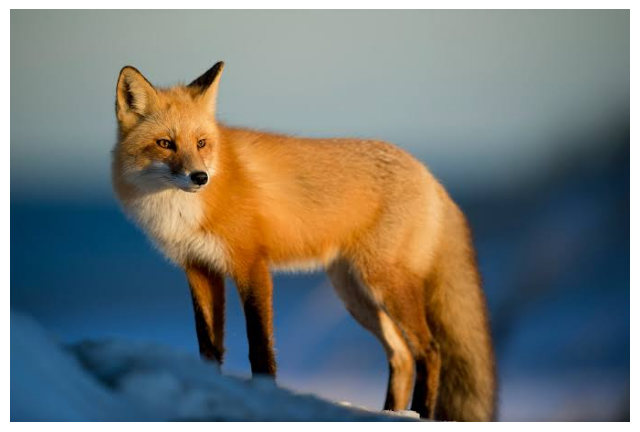

In [ ]:
from PIL import Image

img_fox = Image.open("fox.jpg")

plt.rcParams["figure.figsize"] = (8, 8)
plt.imshow(img_fox)
plt.axis("off")
plt.show()

Преобразуем изображение в тензор и подадим на вход модели:

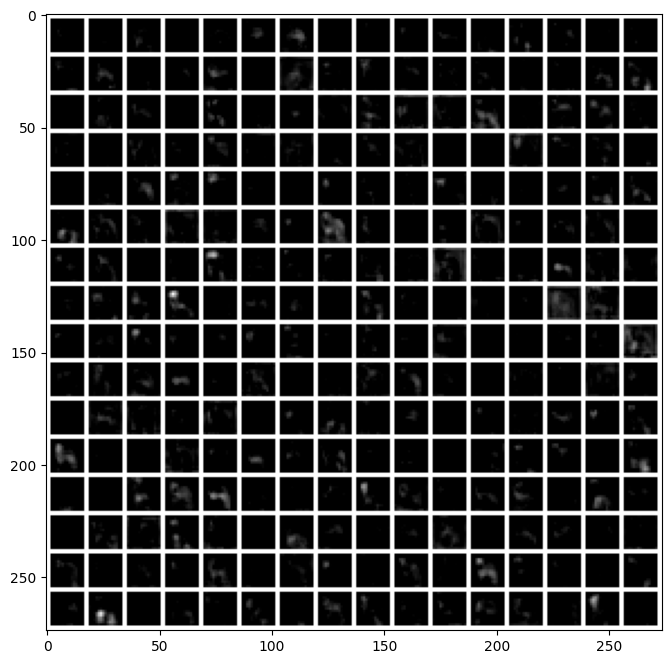

In [ ]:
from torchvision.transforms import v2


transform = v2.Compose(
    [
        v2.Resize((256, 256)),
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
    ]
)

tensor = transform(img_fox)
out = alexnet(tensor.unsqueeze(0))

Тут уже можно увидеть некоторые паттерны. Видно, что многие фильтры реагируют на лисицу.

Единственная опасная ловушка, которую можно легко заметить с помощью этой визуализации, заключается в том, что некоторые карты признаков могут быть равны нулю для многих различных входов. Это может указывать на мертвые фильтры и быть симптомом слишком высокой скорости обучения.

Отключим наш hook, чтобы он не мешал дальнейшим экспериментам:

In [ ]:
handle.remove()

Существуют техники, которые позволяют визуализировать паттерн, на который лучше всего активируется конкретный нейрон. Они основаны на подсчете градиента не по весам, а по входу (изображению) и его постепенной модификации.

Примеры:

* [[demo] 🎮 Exploring Neural Networks with Activation Atlases](https://distill.pub/2019/activation-atlas/)

* [[blog] ✏️ Feature Visualization](https://distill.pub/2017/feature-visualization/)


# Аугментации

Операция свертки инвариантна к сдвигу (неважно, где на изображении находится объект), но не к масштабированию и повороту.


У этой проблемы нет красивого решения: если в обучающей выборке не было котов, висящих вверх лапами, то модель не будет их различать.

Нужно дополнить датасет такими изображениями, и самый простой способ это сделать — это преобразовать (отразить, повернуть, масштабировать и т.д.) уже имеющиеся.

**Аугмента́ция** (от лат. augmentatio — увеличение, расширение) — увеличение выборки обучающих данных через модификацию существующих данных.

Модели глубокого обучения обычно требуют большого количества данных для обучения. В целом, чем больше данных, тем лучше для обучения модели. В то же время получение огромных объемов данных сопряжено с проблемами (например, с нехваткой размеченных данных или с трудозатратами, сопряженными с разметкой).

Вместо того, чтобы тратить время на сбор данных вручную, мы можем использовать методы аугментации для автоматической генерации новых примеров из уже имеющихся.

Помимо увеличения размеченных датасетов, многие методы *self-supervised learning* построены на использовании разных аугментаций одного и того же семпла.

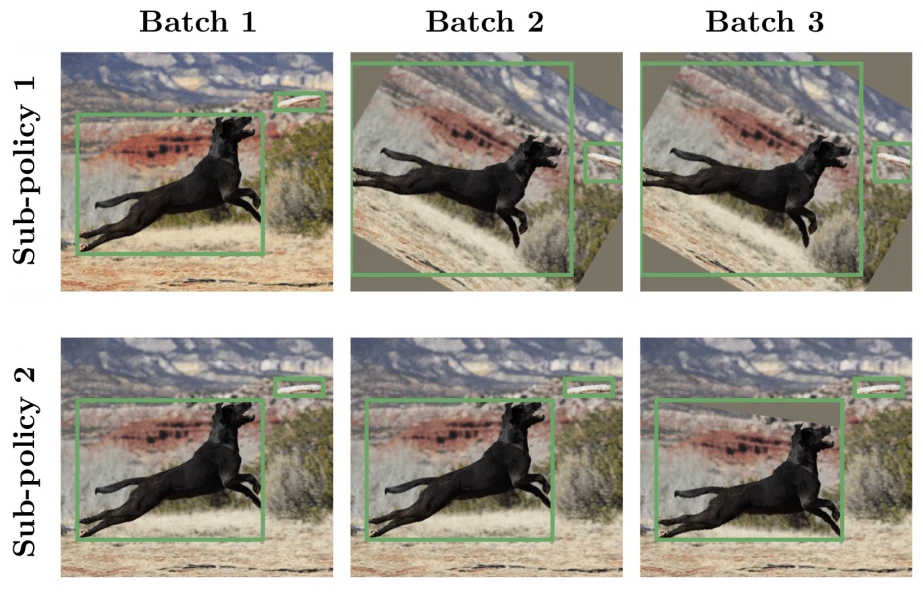

**Важный момент**: при обучении модели мы используем разбиение данных на `train-val-test`. Аугментации стоит применять только на `train`. Почему так? Конечная цель обучения нейросети — это применение на реальных данных, которые сеть не видела. Поэтому для адекватной оценки качества модели валидационные и тестовые данные изменять не нужно.

В любом случае, `test` должен быть отделен от данных еще до того, как они попали в `DataLoader` или нейросеть.

Другое дело, что аугментации на тесте можно использовать как метод ансамблирования в случае классификации. Можно:

взять sample → создать несколько его копий → по-разному их аугментировать → предсказать класс на каждой из этих аугментированных копий → выбрать наиболее вероятный класс голосованием.

Такой функционал реализован, например, в YOLO, о которой речь пойдет в следующих лекциях.

Инструментарий для аугментаций [встроен в PyTorch 🛠️[doc]](https://pytorch.org/vision/stable/transforms.html). Мы уже пользовались им, когда создавали датасет и передавали в конструктор параметр **transform**.

In [ ]:
import torch
from torchvision.transforms import v2


transform = v2.Compose(
    [
        v2.Resize(224),
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ]
)



Собственно, экземпляр объекта `torchvision.transforms.v2.Resize`, созданный первым в списке (`v2.Resize(224)`), и аугментирует изображение.

*Отметим что аугментация происходит "на лету": аугментированное изображение не сохраняется на диск и сразу передается в модель.*

Пакет `torchvision.transforms.v2` [🛠️[doc]](https://pytorch.org/vision/0.9/transforms.html) позволяет выполнить  довольно много различных аугментаций. Посмотрим на некоторые из них.



Загрузим и отобразим пример картинки. Картинку отмасштабируем, чтобы она не занимала весь экран.

In [ ]:
# Setting random seed for reproducible illustrations
!wget -q https://raw.githubusercontent.com/alexkalitenko125/Course-Neural-Networks-in-Quantum-Theory/refs/heads/main/capybara.jpg

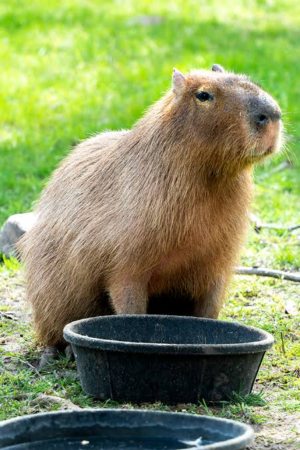

In [ ]:
from PIL import Image
from IPython.display import display

input_img = Image.open("capybara.jpg")
input_img = v2.Resize(size=300)(input_img)
display(input_img)

Рассмотрим несколько примеров аугментаций картинок. С полным списком можно ознакомиться на сайте [документации torchvision 🛠️[doc]](https://pytorch.org/vision/stable/auto_examples/transforms/plot_transforms_illustrations.html#sphx-glr-auto-examples-transforms-plot-transforms-illustrations-py). Отметим, что более актуальной версией сейчас является `transforms.v2`, которую мы и будем использовать.

#### Random Rotation

Трансформация `transforms.v2.RandomRotation` [🛠️[doc]](https://pytorch.org/vision/main/generated/torchvision.transforms.v2.RandomRotation.html) принимает параметр `degrees` — диапазон углов, из которого выбирается случайный угол для поворота изображения.

Создадим переменную `transform`, в которую добавим нашу аугментацию, и применим ее к исходному изображению. Затем запустим следующую ячейку несколько раз подряд

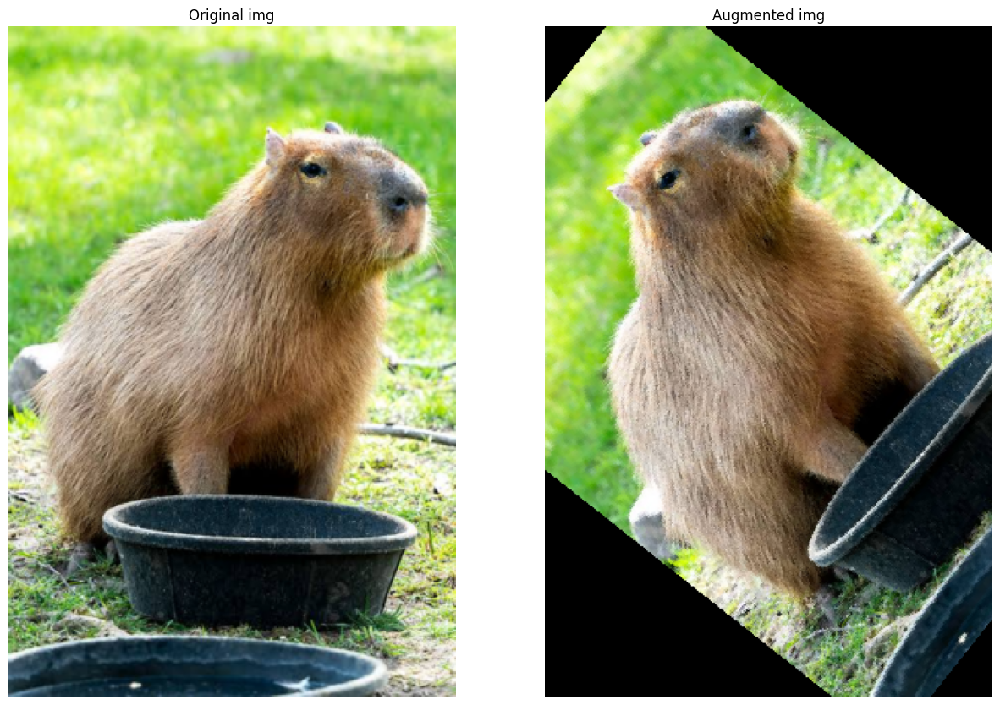

In [ ]:
import matplotlib.pyplot as plt


def plot_augmented_img(transform, input_img):
    fig, ax = plt.subplots(1, 2, figsize=(15, 15))
    augmented_img = transform(input_img)
    ax[0].imshow(input_img)
    ax[0].set_title("Original img")
    ax[0].axis("off")

    ax[1].imshow(augmented_img)
    ax[1].set_title("Augmented img")
    ax[1].axis("off")
    plt.show()


transform = v2.RandomRotation(degrees=(0, 180))

plot_augmented_img(transform, input_img)

#### Gaussian Blur

`transforms.v2.GaussianBlur` [🛠️[doc]](https://pytorch.org/vision/main/generated/torchvision.transforms.v2.GaussianBlur.html) размывает изображение с помощью фильтра Гаусса.

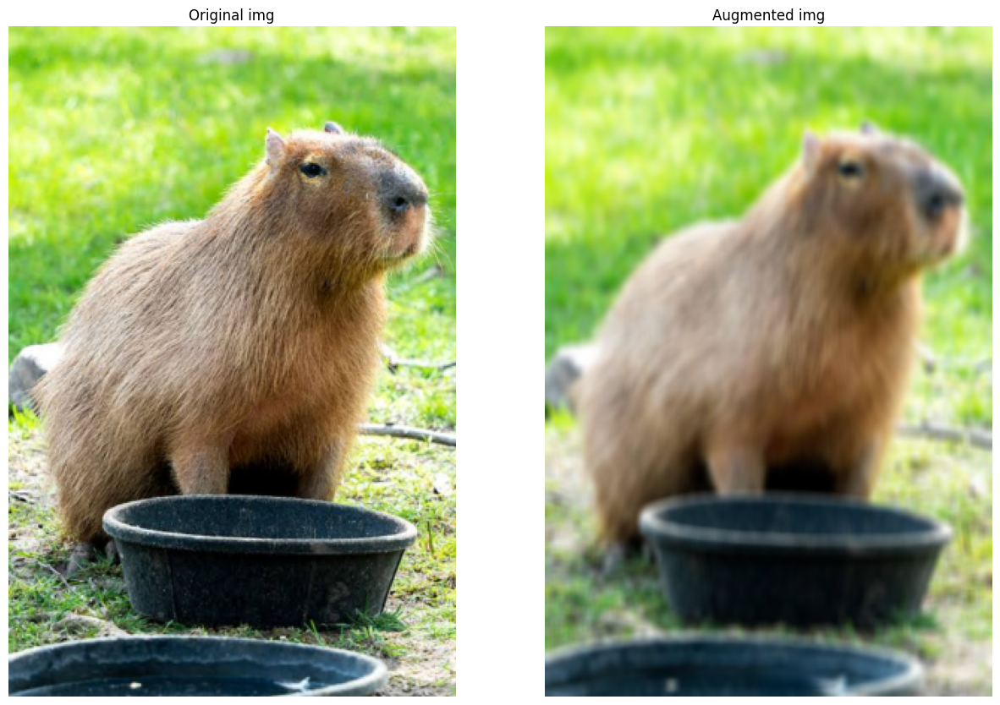

In [ ]:
transform = v2.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5))

plot_augmented_img(transform, input_img)

#### Random Erasing

`transforms.v2.RandomErasing` [🛠️[doc]](https://pytorch.org/vision/main/generated/torchvision.transforms.v2.RandomErasing.html) стирает на изображении произвольный прямоугольник. Она имеет параметр `p` — вероятность, с которой данная трансформация вообще применится к изображению.

Данная трансформация работает только с `torch.Tensor`, поэтому предварительно нужно применить трансформации `ToImage()`, `ToDtype(torch.float32, scale=True)`, а затем `ToPILImage()`, чтобы воспользоваться нашей функцией для отображения.



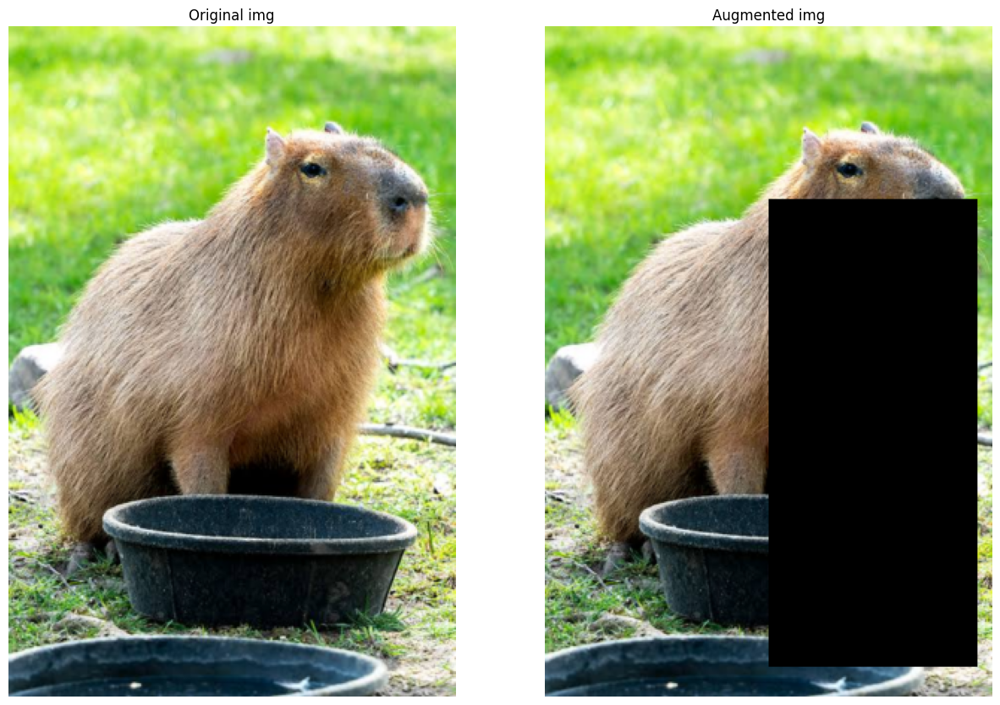

In [ ]:
transform = v2.Compose(
    [
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.RandomErasing(p=1),
        v2.ToPILImage(),
    ]
)

plot_augmented_img(transform, input_img)

Не лишним будет заметить, что некоторые трансформации могут существенно исказить изображение. Например, здесь `RandomErasing` практически полностью стерла основной объект на снимке — капибару. Такая грубая аугментация может только навредить процессу обучения, и на практике нужно быть осторожным.

`RandomErasing` также имеет параметр `scale` — диапазон соотношения стираемой области к входному изображению. Попробуем уменьшить этот диапазон относительно значения по умолчанию, чтобы избежать нежелательного эффекта стирания капибары.

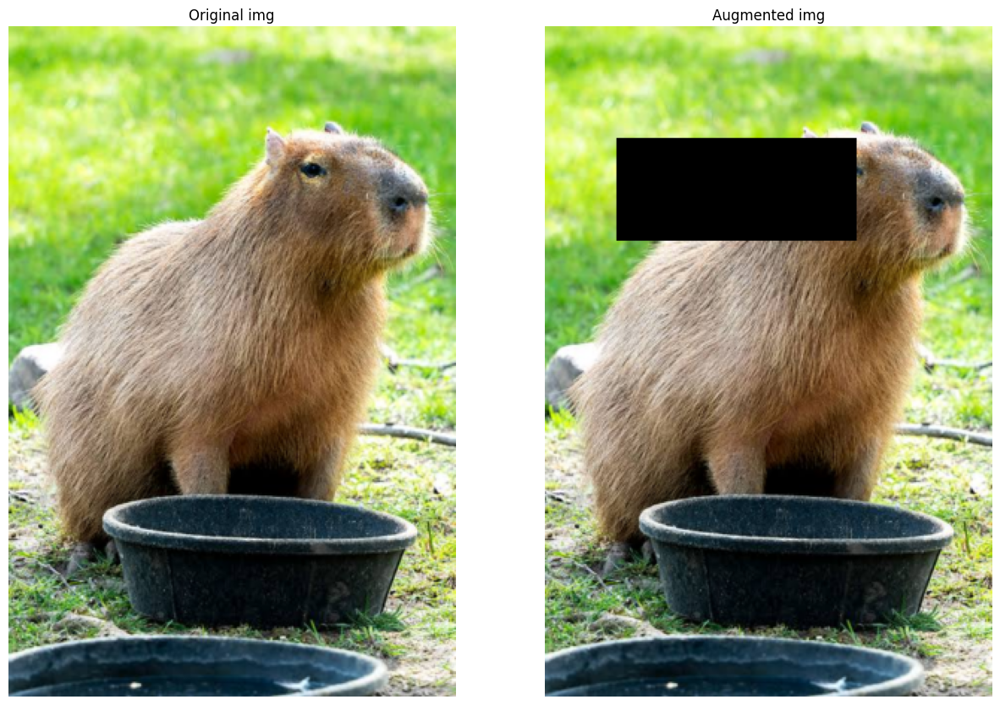

In [ ]:
transform = v2.Compose(
    [
        v2.ToImage(),
        v2.ToDtype(torch.float32, scale=True),
        v2.RandomErasing(p=1, scale=(0.02, 0.1)),
        v2.ToPILImage(),
    ]
)

plot_augmented_img(transform, input_img)

#### Color Jitter
`transforms.v2.ColorJitter` [🛠️[doc]](https://pytorch.org/vision/main/generated/torchvision.transforms.v2.ColorJitter.html) случайным образом меняет яркость, контрастность, насыщенность и оттенок изображения.

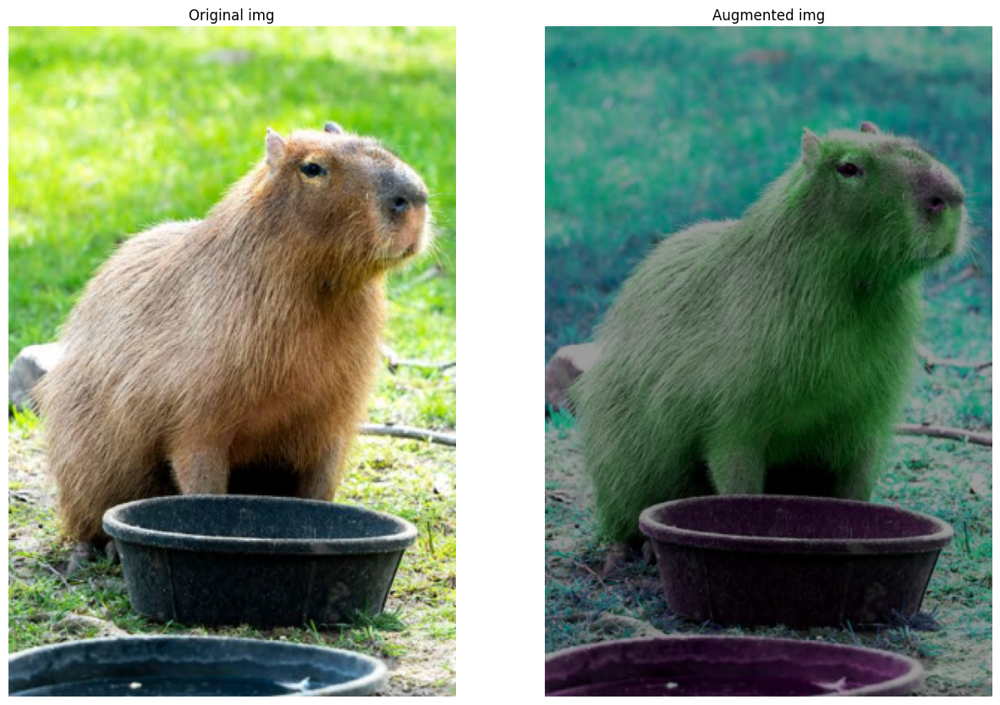

In [ ]:
transform = v2.ColorJitter(brightness=0.5, hue=0.3)

plot_augmented_img(transform, input_img)

#### Совмещаем несколько аугментаций вместе

Для этого будем использовать метод `transforms.v2.Compose` [🛠️[doc]](https://pytorch.org/vision/main/generated/torchvision.transforms.v2.Compose.html), с которым мы хорошо знакомы. Нам нужно будет создать `list` со всеми аугментациями, которые будут применены последовательно.

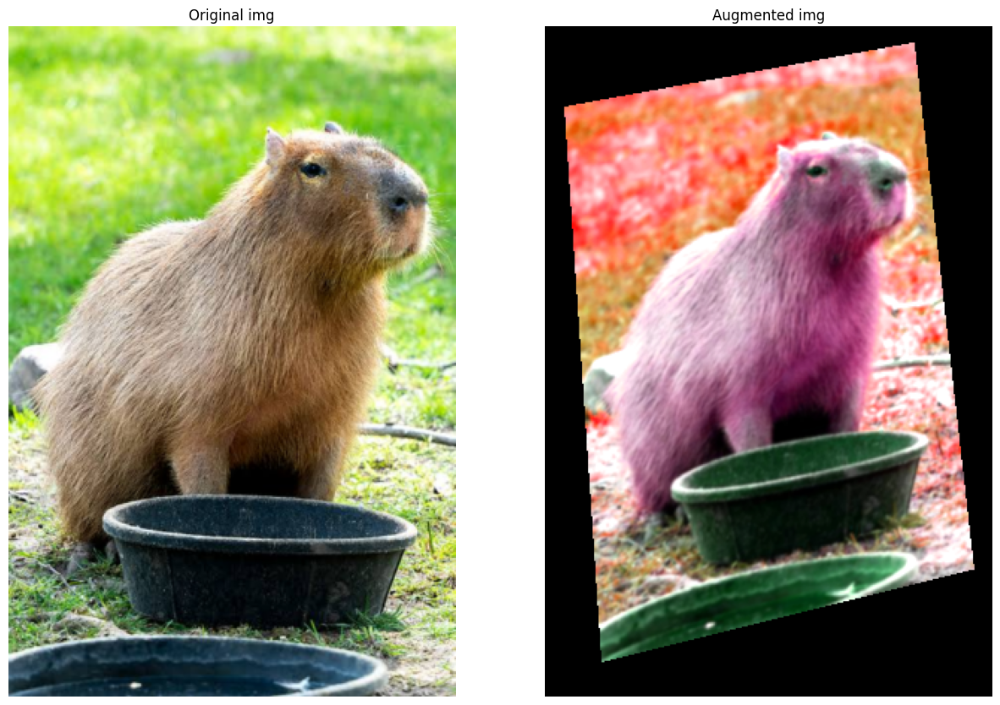

In [ ]:
transform = v2.Compose(
    [
        v2.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5)),
        v2.RandomPerspective(distortion_scale=0.5, p=1.0),
        v2.ColorJitter(brightness=0.5, hue=0.3),
    ]
)

plot_augmented_img(transform, input_img)

#### Совмещение нескольких аугментаций случайным образом

Как видно, три аугментации, примененные последовательно, достаточно сильно изменили картинку. Разумнее применять не все сразу. Для этого есть соответствующие классы.

##### <font size="4">Random Apply</font>

Для того, чтобы применять аугментации случайным образом, можно воспользоваться классом `transforms.v2.RandomApply` [🛠️[doc]](https://pytorch.org/vision/stable/generated/torchvision.transforms.v2.RandomApply.html), конструктор которого принимает на вход  список аугментаций и вероятность `p`, с которой каждая аугментация будет применена.

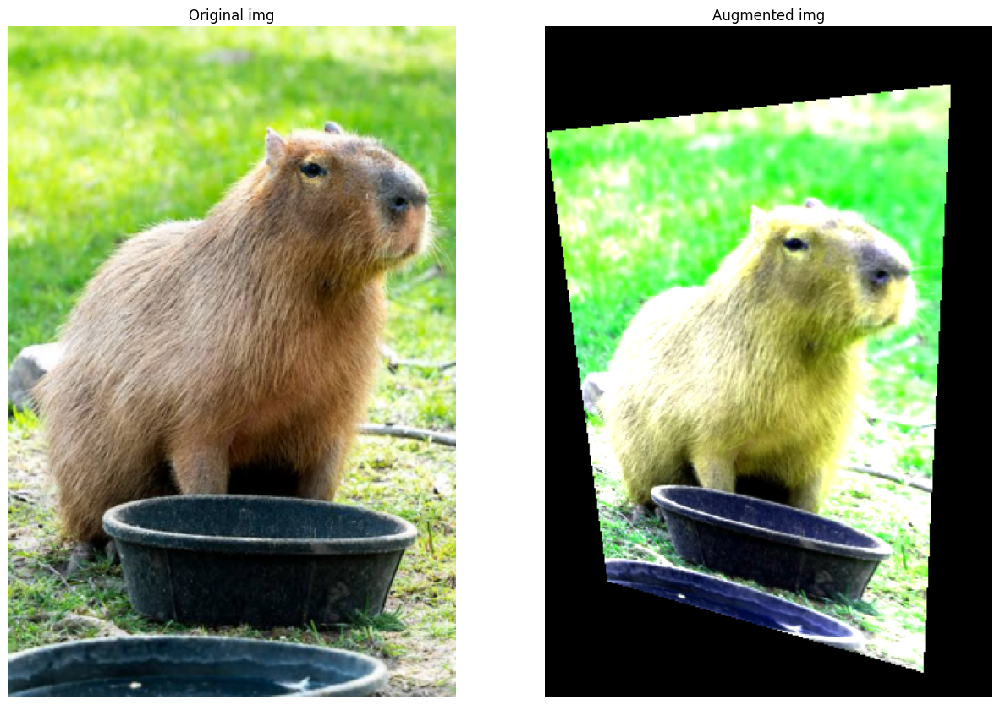

In [ ]:
transform = v2.RandomApply(
    transforms=[
        v2.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5)),
        v2.RandomPerspective(distortion_scale=0.5),
        v2.ColorJitter(brightness=0.5, hue=0.3),
    ],
    p=0.9,
)

plot_augmented_img(transform, input_img)

##### <font size="4">Random Choice</font>

В других случаях может быть полезен класс `transforms.v2.RandomChoice` [🛠️[doc]](https://pytorch.org/vision/main/generated/torchvision.transforms.v2.RandomChoice.html), конструктор которого принимает на вход список аугментаций `transforms.v2`, выбирает из него **одну** случайную аугментацию и применяет ее к изображению. Необязательным параметром является список вероятностей `p`, который указывает, с какой вероятностью каждая из аугментаций может быть выбрана из списка (по умолчанию каждая может быть выбрана равновероятно).

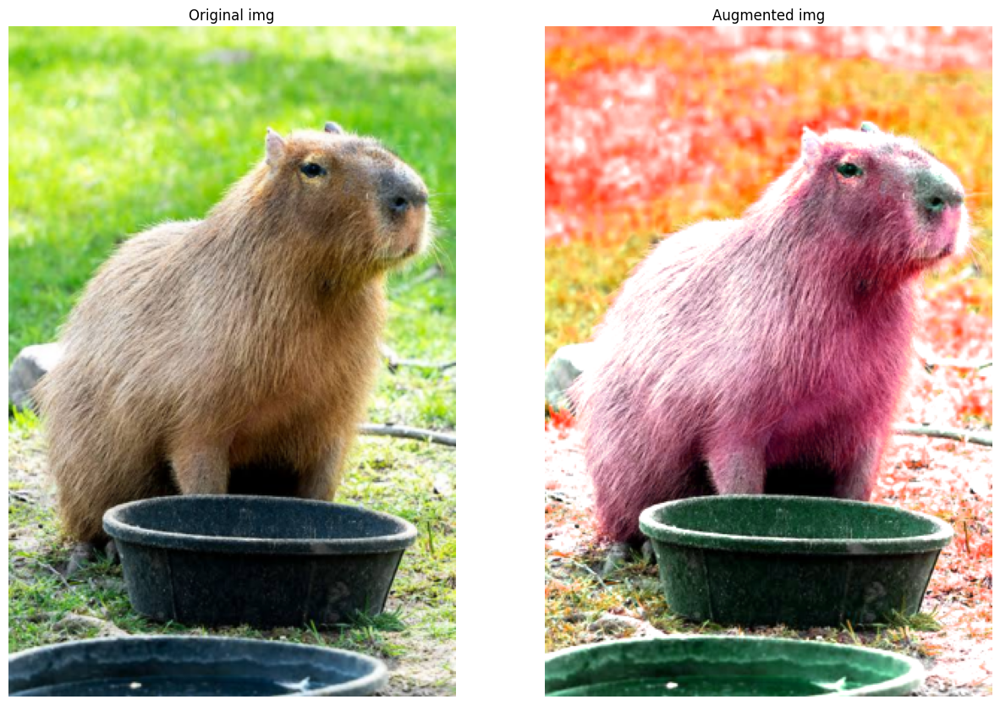

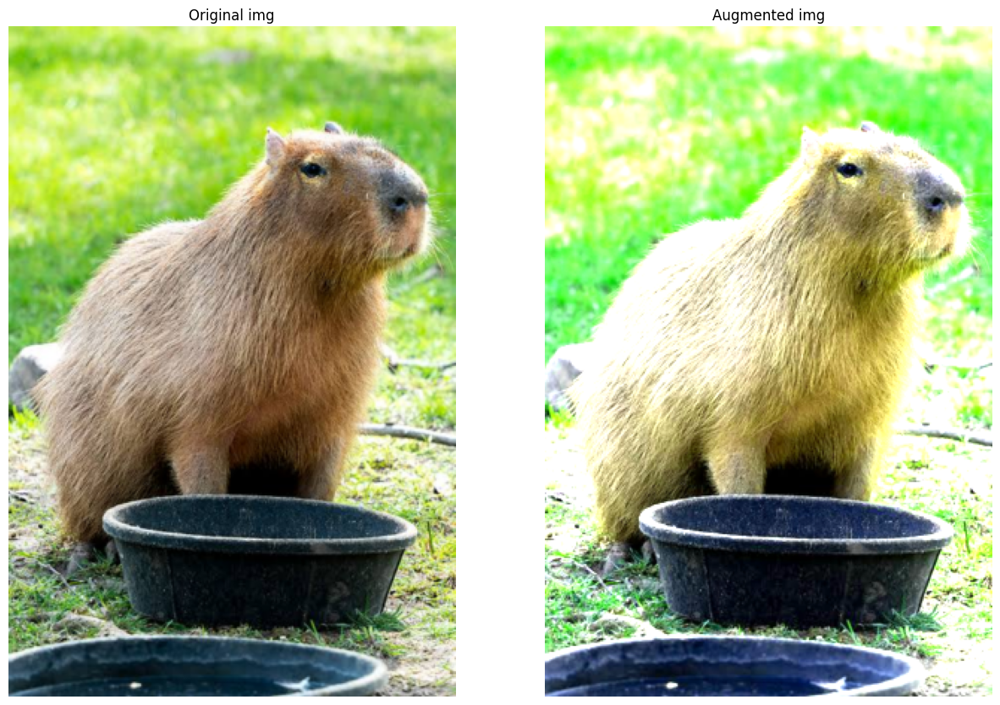

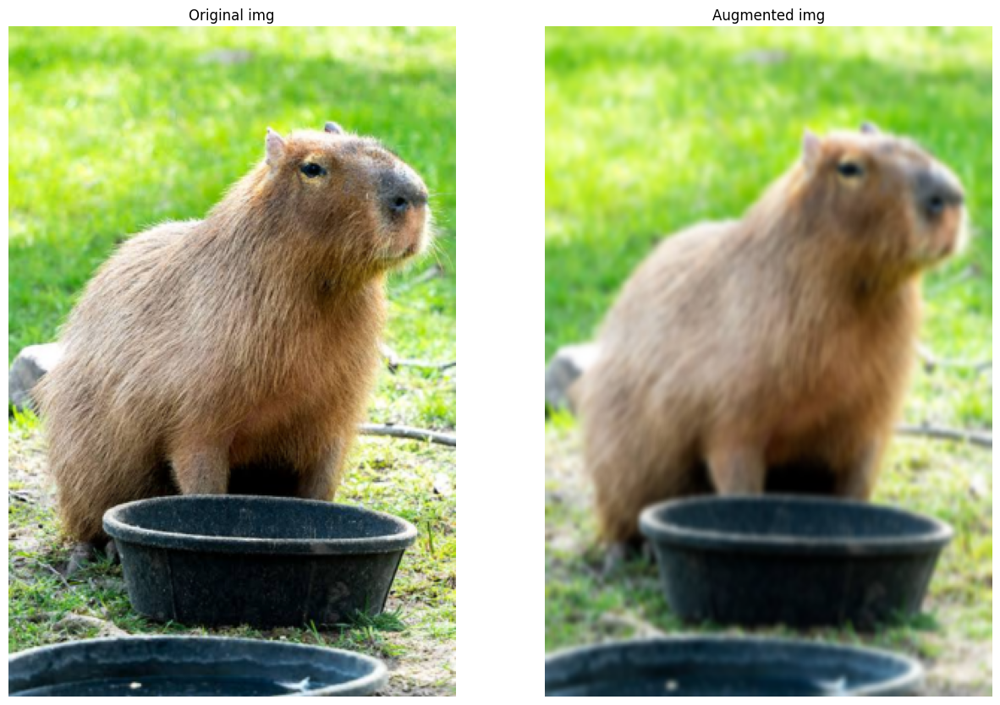

In [ ]:
transform = v2.RandomChoice(
    transforms=[
        v2.GaussianBlur(kernel_size=(5, 9), sigma=(0.1, 5)),
        v2.RandomPerspective(distortion_scale=0.5, p=1.0),
        v2.ColorJitter(brightness=0.5, hue=0.3),
    ],
    p=[0.2, 0.4, 0.6],
)

plot_augmented_img(transform, input_img)
plot_augmented_img(transform, input_img)
plot_augmented_img(transform, input_img)

#### Пример создания собственной аугментации

Иногда может оказаться, что среди широкого спектра реализованных аугментаций нет такой, которую вы хотели бы применить к своим данным. В таком случае ее можно описать в виде класса и использовать наравне с реализованными в библиотеке.

Главное, что необходимо описать при создании класса, — метод `__call__`. Он должен принимать изображение (оно может быть представлено в формате `PIL.Image`, `np.array` или `torch.Tensor`), делать с ним интересующие нас видоизменения и возвращать измененное изображение.

Рассмотрим пример добавления на изображение [шума "соль и перец" 📚[wiki]](https://ru.wikipedia.org/wiki/Salt_and_pepper). Наш метод аугментации будет и принимать на вход, и возвращать `PIL.Image`.



In [ ]:
import numpy as np
from PIL import Image


class SaltAndPepperNoise:
    """
    Add a "salt and pepper" noise to the PIL image
    __call__ method returns PIL Image with noise
    """

    def __init__(self, p=0.01):
        self.p = p  # noise level

    def __call__(self, pil_image):
        np_image = np.array(pil_image)

        # Create random mask for "salt" and "pepper" pixels
        salt_ind = np.random.choice(
            a=[True, False], size=np_image.shape[:2], p=[self.p, 1 - self.p]
        )
        pepper_ind = np.random.choice(
            a=[True, False], size=np_image.shape[:2], p=[self.p, 1 - self.p]
        )

        # Add "salt" and "pepper"
        np_image[salt_ind] = 255
        np_image[pepper_ind] = 0

        return Image.fromarray(np_image)

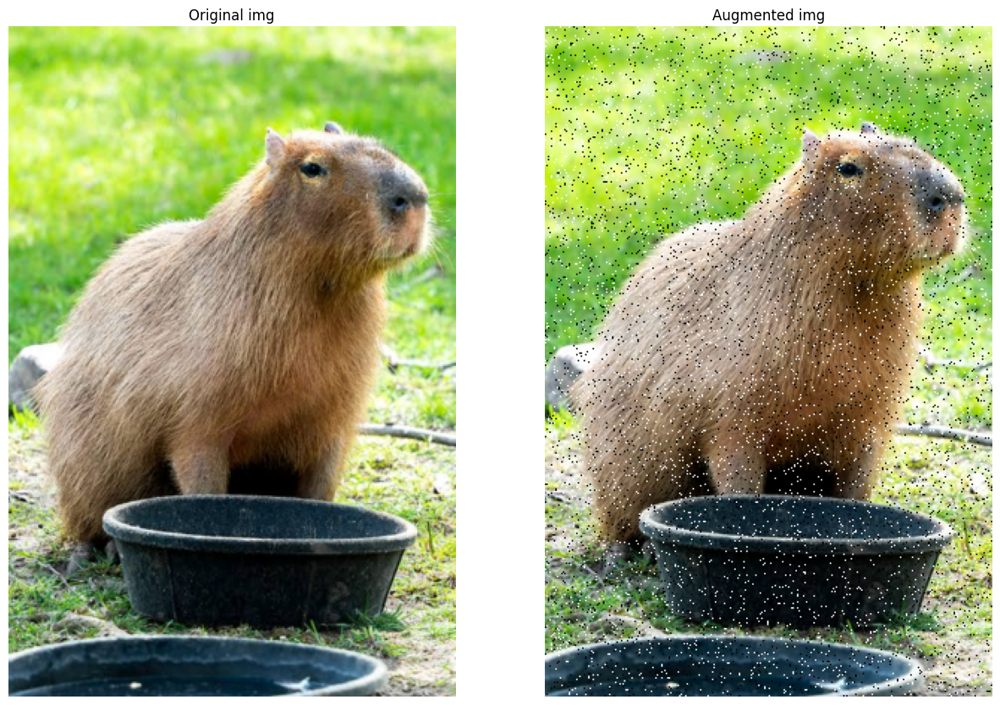

In [ ]:
transform = SaltAndPepperNoise(p=0.03)

plot_augmented_img(transform, input_img)

#### Аугментация в реальных задачах

Кроме методов, реализованных в PyTorch, существуют и специализированные библиотеки для аугментации изображений, в которых реализованы дополнительные возможности (например, наложение теней, бликов или пятен воды на изображение).

Например:
- [[doc] 🛠️ Albumentations](https://albumentations.ai)
- [[doc] 🛠️ imgaug](https://imgaug.readthedocs.io/en/latest/index.html)
- [[doc] 🛠️ AugLy](https://github.com/facebookresearch/AugLy)

**Важно: при выборе методов аугментации имеет смысл использовать только те, которые будут в реальной жизни.**

Например, нет смысла:
- делать перевод изображения в черно-белое, если предполагается, что весь входящий поток будет цветным,
- отражать человека вверх ногами, если мы не предполагаем его таким распознавать.

# Практические рекомендации

*   Используйте [готовые модели 🛠️[doc]](https://pytorch.org/vision/stable/models.html).
*   Используйте фильтры $3 \times 3 $ — они работают быстрее и эффективнее на практике, используют меньше ресурсов.
*   Чтобы уменьшить пространственные размеры, используйте свертку со `stride = 2`.
*   Чтобы уменьшить количество карт признаков, используйте свертку $1 \times 1$.
*   Сохраняйте логи и следите за ходом обучения при помощи инструментов [TensorBoard 🛠️[doc]](https://pytorch.org/tutorials/intermediate/tensorboard_tutorial.html) и [Weights&Biases 🛠️[doc]](https://wandb.ai/site).
*   Отлаживайте код на на части датасета: `debug_train, debug_val, _ = random_split(dataset, [5000, 1000, 54000])`.

<font size=6>Литература</font>

https://msu.ai/convolutional_neural_networks

<font size=5>Распознавание квантовых фазовых переходов с помощью сверточных нейронных сетей (CNN) :</font>
https://journals.jps.jp/doi/10.7566/JPSJ.86.063001

<font size=5>Введение в сверточные нейронные сети:</font>

* [[blog] ✏️ Всё, что вы хотели знать о перцептронах Розенблатта, но боялись спросить](https://habr.com/ru/companies/sberdevices/articles/529932/)
* [[wiki] 📚 Viola–Jones object detection framework](https://en.wikipedia.org/wiki/Viola%E2%80%93Jones_object_detection_framework)

<font size=5>Сверточный слой нейросети:</font>

* [[blog] ✏️ Какого цвета Марс?](https://habr.com/ru/articles/160621/s)

<font size=5>Применение свёрточных слоёв:</font>

* [[doc] 🛠️ LeNet PyTorch documentation](https://pytorch.org/tutorials/beginner/blitz/neural_networks_tutorial.html)

<font size=5>Другие виды сверток:</font>

* [[blog] ✏️ Convolution vs. Cross-Correlation](https://glassboxmedicine.com/2019/07/26/convolution-vs-cross-correlation/)
* [[blog] ✏️ 2D Convolution as a Matrix-Matrix Multiplication](https://www.baeldung.com/cs/convolution-matrix-multiplication)
* [[blog] ✏️ Forward and Backward Convolution Passes as Matrix Multiplication](https://danieltakeshi.github.io/2019/03/09/conv-matmul/)
* [[blog] ✏️ The NIFTI file format](https://brainder.org/2012/09/23/the-nifti-file-format/)
* [[doc] 🛠️ NiBabel](https://nipy.org/nibabel/coordinate_systems.html)
* [[doc] 🛠️ PyTorch Geometric](https://pytorch-geometric.readthedocs.io/en/latest/)
* [[wiki] 📚 Adjacency matrix](https://en.wikipedia.org/wiki/Adjacency_matrix)
* [[doc] 🛠️ Drawing — basic functionality for visualizing graphs](https://networkx.org/documentation/networkx-1.10/reference/drawing.html)
* [[arxiv] 🎓 Semi-Supervised Classification with Graph Convolutional Networks](https://arxiv.org/abs/1609.02907).
* [[doc] 🛠️ GNN Cheatsheet](https://pytorch-geometric.readthedocs.io/en/latest/notes/cheatsheet.html)

<font size=5>Визуализация:</font>

* [[arxiv] 🎓 Understanding Neural Networks Through Deep Visualization](https://arxiv.org/abs/1506.06579)
* [[demo] 🎮 Exploring Neural Networks with Activation Atlases](https://distill.pub/2019/activation-atlas/)
* [[blog] ✏️ Feature Visualization](https://distill.pub/2017/feature-visualization/)

<font size=5>Lightning:</font>

* [[git] 🐾 Lightning](https://github.com/Lightning-AI/lightning)
* [[doc] 🛠️ TensorBoard](https://pytorch.org/tutorials/intermediate/tensorboard_tutorial.html)
* [[doc] 🛠️ Weights&Biases](https://wandb.ai/site)

<font size=5>Дополнительно:</font>

* [[blog] ✏️ Свёртка в Deep Learning простыми словами](https://www.reg.ru/blog/svyortka-v-deep-learning-prostymi-slovami)
* [[arxiv] 🎓 A guide to convolution arithmetic for deep
learning](https://arxiv.org/pdf/1603.07285v1.pdf)
* [[video] 📺 But what is a convolution?](https://www.youtube.com/watch?v=KuXjwB4LzSA)
* [[video] 📺 Fundamental Algorithm of Convolution in Neural Networks](https://www.youtube.com/watch?v=eMXuk97NeSI&list=PLZDCDMGmelH-pHt-Ij0nImVrOmj8DYKbB)